Goal of this notebook is to make a generic, easy to use alpha alignment. Input the Tiff stack to be aligned.

In [1]:
## IMPORTS
import numpy as np
import math
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
import tifffile
from sklearn.cluster import KMeans
import matplotlib as mpl
import matplotlib.pyplot as plt
import cv2
#from tqdm import tqdm
from scipy.fft import fftn, ifftn
from scipy.ndimage import fourier_shift, gaussian_filter
from scipy.ndimage import shift as img_shift
from numpy.fft import fftshift
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import curve_fit
import gc
import psutil

from skimage.feature import graycomatrix, graycoprops
from skimage import io

import scipy.ndimage as ndimage


In [2]:
## FUNCTIONS
def calculate_centroid(image):
    # Ensure the image is a numpy array
    image = np.array(image, dtype=np.float64)

    # Get the indices of the image array
    y_indices, x_indices = np.indices(image.shape)   

    # Calculate the centroid coordinates
    total_intensity = np.sum(image)
    x_centroid = np.sum(x_indices * image) / total_intensity
    y_centroid = np.sum(y_indices * image) / total_intensity

    return y_centroid, x_centroid

def calculate_centroid_0(image):
    # Ensure the image is a numpy array
    image = np.array(image, dtype=np.float64)

    zero_mask = (image == 0).astype(np.float64)

    # Get the indices of the image array
    y_indices, x_indices = np.indices(image.shape)  

    total_intensity = np.sum(zero_mask)

    if total_intensity == 0:
        raise ValueError ("No zero pixels")

    x_centroid = np.sum(x_indices * image) / total_intensity
    y_centroid = np.sum(y_indices * image) / total_intensity

    return y_centroid, x_centroid

# def find_fiducial_points(image, fiduc_num, verbose=False):
#     factor = 1.25

#     valid_mask = np.isfinite(image)  # excludes NaNs
#     # If zero-padding is also problematic, uncomment:
#     # valid_mask &= (image != 0)

#     if not np.any(valid_mask):
#         # No valid pixels at all
#         return np.full((fiduc_num, 2), np.nan)

        
#     hole_thresh = image.max()/factor
#     hole_mask = np.zeros_like(image)
#     hole_mask[image > hole_thresh] = 1.0
    
#     # Using Clustering to identify the 4 different holes
#     height, width = image.shape
    
#     # k_data = []
#     # for i in range(width):
#     #     for j in range(height):
#     #         if hole_mask[j,i] > 0:
#     #             k_data.append((j, i))


#     # --- Collect candidate pixels ---
#     k_data = np.column_stack(np.where(hole_mask > 0))  # shape (N, 2)
#     if k_data.shape[0] < fiduc_num:
#         print('Not enough points to cluster')
#         return np.full((fiduc_num, 2), np.nan)

        
#     kmeans = KMeans(n_clusters=fiduc_num, n_init=5) # Emma added n_init=5  to minimize crashing 
#     kmeans.fit(k_data)
    
#     k_data = np.array(k_data)

#     if verbose:
#         print('creating figures')
#         fig_size = 5
#         fig, axes = plt.subplots(1, 2, figsize=(fig_size * 2.2, fig_size))
#     fiduc_points = []
#     for i in range(fiduc_num):
#         cluster_group = k_data[kmeans.labels_ == i]
#         x_data = cluster_group[:,1]
#         y_data = cluster_group[:,0]
#         temp_mask = np.zeros_like(image)
#         temp_mask[y_data, x_data] = 1.0
#         y_centroid, x_centroid = calculate_centroid(temp_mask)
#         fiduc_points.append((y_centroid, x_centroid)) 

#         if verbose:
#             axes[0].scatter(x_data, y_data)
#             axes[0].plot(x_centroid, y_centroid, linestyle="", marker='+', color='black')
        
#     fiduc_points = np.array(fiduc_points)

#     if verbose:
#         axes[0].set_xlabel('X (px)')
#         axes[0].set_ylabel('Y (px)')
#         axes[0].set_title("Clustered Points")
        
#         axes[1].imshow(hole_mask)
#         axes[1].plot(fiduc_points[:,1], fiduc_points[:,0], linestyle="", marker='+', color='red')
#         axes[1].axis('off')
#         axes[1].set_title ("Image")
#         plt.show()

#     return fiduc_points
    
def find_fiducial_points(image, fiduc_num, verbose=False):
    factor = 1.25

    # --- Valid pixel mask ---
    valid_mask = np.isfinite(image)
    # If zero padding is also bad, uncomment:
    # valid_mask &= (image != 0)

    if not np.any(valid_mask):
        return np.full((fiduc_num, 2), np.nan)

    # --- Threshold using only valid pixels ---
    hole_thresh = np.nanmax(image[valid_mask]) / factor

    hole_mask = np.zeros_like(image, dtype=np.uint8)
    hole_mask[(image > hole_thresh) & valid_mask] = 1

    # --- Collect candidate pixels ---
    k_data = np.column_stack(np.where(hole_mask > 0))  # shape (N, 2)

    if k_data.shape[0] < fiduc_num:
        print('Not enough points to cluster')
        return np.full((fiduc_num, 2), np.nan)

    # --- KMeans ---
    kmeans = KMeans(n_clusters=fiduc_num, n_init=5)
    kmeans.fit(k_data)

    if verbose:
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    fiduc_points = []

    for i in range(fiduc_num):
        cluster = k_data[kmeans.labels_ == i]

        if cluster.size == 0:
            fiduc_points.append((np.nan, np.nan))
            continue

        y_data = cluster[:, 0]
        x_data = cluster[:, 1]

        temp_mask = np.zeros_like(image, dtype=np.uint8)
        temp_mask[y_data, x_data] = 1

        y_c, x_c = calculate_centroid(temp_mask)
        fiduc_points.append((y_c, x_c))

        if verbose:
            axes[0].scatter(x_data, y_data)
            axes[0].plot(x_c, y_c, '+k')

    fiduc_points = np.array(fiduc_points)

    if verbose:
        axes[0].set_title("Clustered fiducials")
        axes[1].imshow(hole_mask)
        axes[1].plot(fiduc_points[:, 1], fiduc_points[:, 0], '+r')
        plt.show()

    return fiduc_points
    
def perspectiveTransform_alignment(first_image, first_points, second_image, second_points, verbose=False):
    ## Returns the second image after it has been transformed to align with the first image
    # Points are clustered in a non=uniform order, so need to group them accordingly
    src_points = []
    dst_points = []
    for point in first_points:
        dists = np.linalg.norm(second_points - point, axis=1)
        index = np.argmin(dists)
    
        src_points.append(point)
        dst_points.append(second_points[index])
    
    src_points = np.array(src_points, dtype='float32')
    dst_points = np.array(dst_points, dtype='float32')
    
    # Solving for the transformation between Images
    A = cv2.getPerspectiveTransform(src_points, dst_points)
    
    src_pts_reshaped = src_points.reshape(-1, 1, 2)
    transformed = cv2.perspectiveTransform(src_pts_reshaped, A)
    transformed = transformed.reshape(-1, 2)

    if verbose:
        # Compare
        for i in range(len(dst_points)):
            print(f"Target: {dst_points[i]}, Transformed: {transformed[i]}, Diff: {np.abs(dst_points[i] - transformed[i])}")
    
    height, width = first_image.shape
    # Applying the perspective transformation to the first image to align it to the second image
    transformed_image = cv2.warpPerspective(second_image, A, (width, height), flags=cv2.INTER_LANCZOS4, borderMode=cv2.BORDER_REPLICATE)
    
    # Evaluating the transformation's alignment by comparing the difference image before and after alignment
    orig_error = calc_NRMSE(second_image, first_image)
    align_error = calc_NRMSE(transformed_image, first_image)
    
    original_diffMap = second_image - first_image
    aligned_diffMap = transformed_image - first_image

    if verbose:
        norm = mpl.colors.Normalize(vmin=np.nanmin(original_diffMap), vmax=np.nanmax(original_diffMap))
        
        fig_size = 5
        fig, axes = plt.subplots(1, 2, figsize=(fig_size * 2, fig_size))
        axes[0].imshow(original_diffMap, norm=norm)
        axes[0].set_title("Error Before")
        axes[1].imshow(aligned_diffMap, norm=norm)
        axes[1].set_title("Error After")
        plt.show()
        
        print(f"Error Before = {orig_error*100:.2f}%\nError After = {align_error*100:.2f}%")

    return transformed_image

def calc_NRMSE(input_array, ref_array):
    NRMSE = (np.sqrt(np.mean((ref_array - input_array)**2)))/(np.max(ref_array) - np.min(ref_array))     
    return NRMSE

def calculate_centroid_points(points):
    """
    Calculates the centroid of a set of 2D coordinate points.

    Args:
        points: A list of tuples, where each tuple represents a point (x, y).

    Returns:
        A tuple (centroid_x, centroid_y) representing the centroid.
    """
    if not points:
        return None  # Handle empty list case

    sum_x = 0
    sum_y = 0
    num_points = len(points)

    for x, y in points:
        sum_x += x
        sum_y += y

    centroid_x = sum_x / num_points
    centroid_y = sum_y / num_points

    return (centroid_x, centroid_y)

# def sin_fit(x, A, yo, phase, b): 
#     # x = theta
#     return A*np.sin(b*x+phase) + yo

def sin_fit(x, A, yo, phase): 
    # x = theta
    b_fix = np.pi/ np.ptp(x)
    return A*np.sin(b_fix*x+phase) + yo

def lin_fit(x, m, xo): 
    # x = theta
    return m*x +xo

# Load Registered CL-CR or CL+CR and plot

In [3]:

sample = "665"

if sample == '665':
    fiduc_num = 4
    #######################################
    Gamma= "Gamma0"
    date0 = '_3AUG25_check_saturation_n50'
    date1 = date0
    
    data_dir_0 =  f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"
    
    pos_images = f"OD_pospol_stack{date0}.tiff"
    #pos_angles_0 = f"angles_shifted{date1}.txt" #### angles are shifted from pospol to be centered at 0
    neg_images = f"OD_negpol_stack{date0}.tiff"
    angles = f"angles_shifted{date1}.txt"   ##### angles shifted to the real alpha = 0
    
    CC = f"OD_chrgcntrst_stack{date1}.tiff"
    XMCD = f"OD_XMCD_stack{date1}.tiff"
    
    y_centroid_0 = f"center_y_centroid{date1}.txt"
    x_centroid_0 = f"center_x_centroid{date1}.txt"
    
    image_stack_pospol_0 = tifffile.imread(os.path.join(data_dir_0, pos_images))
    image_stack_negpol_0 = tifffile.imread(os.path.join(data_dir_0, neg_images))
    CC_0 = tifffile.imread(os.path.join(data_dir_0, CC))
    XMCD_0 = tifffile.imread(os.path.join(data_dir_0, XMCD))
    angles_0 = np.loadtxt(os.path.join(data_dir_0, angles))
    y_0 = np.loadtxt(os.path.join(data_dir_0, y_centroid_0))
    x_0 = np.loadtxt(os.path.join(data_dir_0, x_centroid_0))
    
    color_0 = 'limegreen'

    #########################################
    Gamma= "Gammaneg45"
    date = '_5AUG25_check_saturation_n50'
    date1 = date
    
    data_dir_neg45 =  f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"
    
    pos_images = f"OD_pospol_stack{date}.tiff"
    # pos_angles_neg45 = f"angles_shifted{date1}.txt" #### angles are shifted from pospol to be centered at 0
    neg_images = f"OD_negpol_stack{date}.tiff"
    angles = f"angles_shifted{date1}.txt"   ##### angles shifted to the real alpha = 0
    
    CC = f"OD_chrgcntrst_stack{date1}.tiff"
    XMCD = f"OD_XMCD_stack{date1}.tiff"
    
    # y_centroid_neg45 = f"center_y_centroid{date1}_v2.txt"
    # x_centroid_neg45 = f"center_x_centroid{date1}_v2.txt"
    y_centroid_neg45 = f"y_centroid{date1}_v2.txt"
    x_centroid_neg45 = f"x_centroid{date1}_v2.txt"
    
    image_stack_pospol_neg45 = tifffile.imread(os.path.join(data_dir_neg45, pos_images))
    image_stack_negpol_neg45 = tifffile.imread(os.path.join(data_dir_neg45, neg_images))
    CC_neg45 = tifffile.imread(os.path.join(data_dir_neg45, CC))
    XMCD_neg45 = tifffile.imread(os.path.join(data_dir_neg45, XMCD))
    angles_neg45 = np.loadtxt(os.path.join(data_dir_neg45, angles))
    y_neg45 = np.loadtxt(os.path.join(data_dir_neg45, y_centroid_neg45))
    x_neg45 = np.loadtxt(os.path.join(data_dir_neg45, x_centroid_neg45))
    
    color_neg45 = 'm'


elif sample == "105":
    print(sample)
    fiduc_num = 3
    #################################################
    Gamma = "Gamma0"
    date = '_17NOV25_auto_select_scans_fullrange_skipped'
    date1 = '_shifted_17NOV25_auto_select_scans_fullrange' 

    data_dir =  f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"

    CC = f"OD_chrgcntrst_stack{date}.tiff"
    XMCD = f"OD_XMCD_stack{date}.tiff"
    
    CC_0 = tifffile.imread(os.path.join(data_dir, CC)) 
    XMCD_0 = tifffile.imread(os.path.join(data_dir, XMCD))
    
    angles_0 = f"angles{date1}.txt"   ##### angles shifted to the real alpha = 0
    
    angles_pospol = np.loadtxt(os.path.join(data_dir, angles_0))
    angles_negpol = np.loadtxt(os.path.join(data_dir, angles_0))

    angles_0 = angles_pospol
    
    print(angles_0.shape)
    print(CC_0.shape)

    
    #################################################
    Gamma = "Gamma45"
    date = '_19NOV25_select_fullrange'
    date1 = '_19NOV25_select_fullrange' 

    data_dir =  f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"

    CC = f"OD_chrgcntrst_stack{date}.tiff"
    XMCD = f"OD_XMCD_stack{date}.tiff"
    
    CC_neg45 = tifffile.imread(os.path.join(data_dir, CC)) 
    XMCD_neg45 = tifffile.imread(os.path.join(data_dir, XMCD))
    
    angles_neg45_neg = f"angles_negpol{date1}.txt"   
    angles_neg45_pos = f"angles_pospol{date1}.txt"   
    
    angles_pospol = np.loadtxt(os.path.join(data_dir, angles_neg45_pos))
    angles_negpol = np.loadtxt(os.path.join(data_dir, angles_neg45_neg))
    
    print(angles_pospol.shape)
    print(CC_neg45.shape)




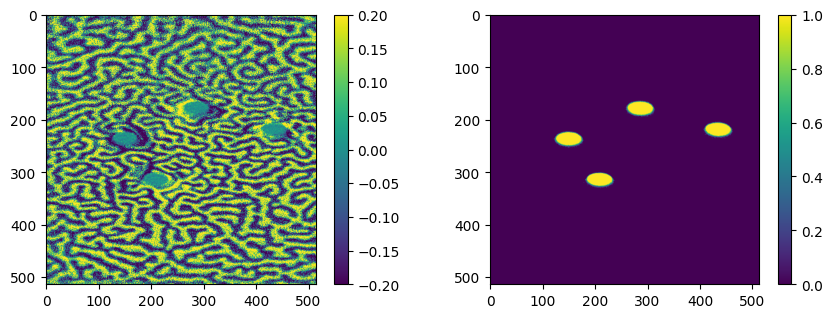

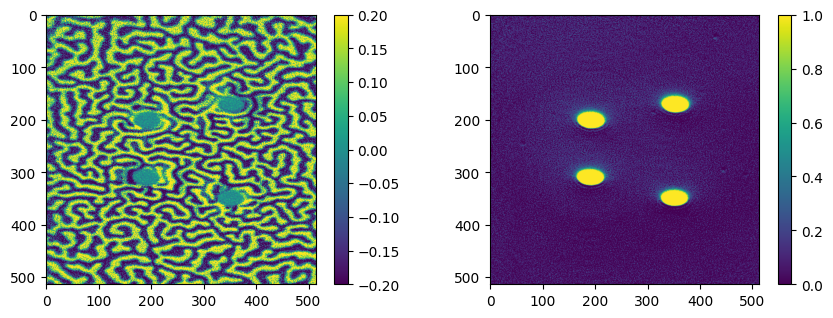

In [4]:
## Plot XMCD and CC of unscaled images
k0 = 10
norm = mpl.colors.Normalize(vmin=-0.2, vmax=0.2)
vmin = 0
vmax = 1
fig_size = 3.5
fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
XMCD = axes[0].imshow(XMCD_neg45[k0], norm=norm)
plt.colorbar(XMCD, ax = axes[0])
CC = axes[1].imshow((CC_neg45[k0]-2)*-1, vmin = vmin, vmax = vmax) 
plt.colorbar(CC, ax = axes[1])
plt.show()

norm = mpl.colors.Normalize(vmin=-0.2, vmax=0.2)
vmin = 0
vmax = 1
fig_size = 3.5
fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
XMCD = axes[0].imshow(XMCD_0[k0], norm=norm)
plt.colorbar(XMCD, ax = axes[0])
CC = axes[1].imshow((CC_0[k0]-2)*-1, vmin = vmin, vmax = vmax) 
plt.colorbar(CC, ax = axes[1])
plt.show()

# Calculate the centroid

## start with one image

(116,)
Calculated centroid using a weighted sum of the Charge Contrast intensity:
 y=244.18894710873707, x = 253.21224570399266
Calculated centroid using kmeans:
 y=259.04586976944745, x = 269.05776401215695


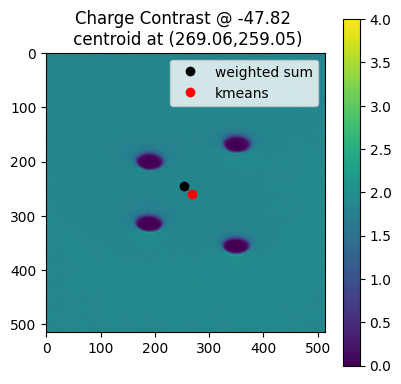

kmeans finds the centroid better


In [5]:
#Select image to look at first
k=12
Gamma = 0
if Gamma == 0:
    CC = CC_0
    XMCD = XMCD_0
    angle = angles_0
    print(angle.shape)
    color1 = 'darkgreen'
    color2 = 'limegreen'
elif Gamma == 45:
    CC = CC_neg45
    XMCD = XMCD_neg45
    angle = angles_neg45
    color1 = 'darkmagenta'
    color2 = 'm'

    
# Calculate the centroid using a weighted sum of the Charge Contrast intensity 
CC_to_fit = (CC[k]-2)*-1
y,x = calculate_centroid(CC_to_fit)
print(f'Calculated centroid using a weighted sum of the Charge Contrast intensity:\n y={y}, x = {x}')
# Calculate the centroid using a kmeans selection of fiducials
points = find_fiducial_points(CC_to_fit, fiduc_num, verbose=False)
tuple_set = set(tuple(row) for row in points)
#print(tuple_set)
y1,x1 = calculate_centroid_points(tuple_set)
print(f'Calculated centroid using kmeans:\n y={y1}, x = {x1}')

# Plot the images to see what each section looks like 
norm_CC = mpl.colors.Normalize(vmin=0, vmax=4)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
img = axes.imshow(CC_to_fit*-1+2,cmap = 'viridis', norm=norm_CC)
axes.plot(x, y, 'ko', label = 'weighted sum')
axes.plot(x1, y1, 'ro', label = 'kmeans')
axes.set_title(f"Charge Contrast @ {angle[k]:.2f} \n centroid at ({x1:.2f},{y1:.2f})") 
fig.colorbar(img)
axes.legend()
plt.show()

print('kmeans finds the centroid better')


## iterate over images

In [6]:
y_centroid= []
x_centroid = []
for k in range(CC.shape[0]): ## select Gamma above

    points = find_fiducial_points(np.nan_to_num(((CC[k]-2)*-1), nan=0.0),fiduc_num,verbose=False)
    tuple_set = set(tuple(row) for row in points)
    y1,x1 = calculate_centroid_points(tuple_set)
    
    y_centroid.append(y1)
    x_centroid.append(x1)

# Shift alpha along the line

(116,)
(116,)
243.78644860689909
[ 21.44897982 256.63665861   4.32432758]
[  3.24063291 276.16583799]
 x = 3.240632908316692*angle + 276.16583798710565


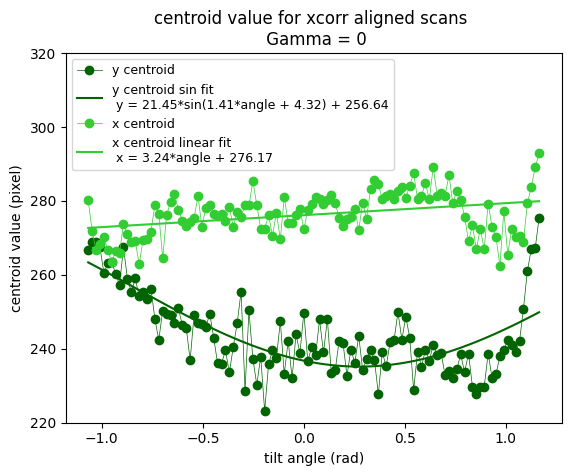

In [7]:
plot_angles = np.linspace(angle[0], np.max(angle), angle.shape[0])
print(plot_angles.shape)
print(np.array(y_centroid).shape)

plot_angles_rad = np.deg2rad(plot_angles)

bounds = ([0, 0, -2*np.pi], [np.inf, np.inf, 2*np.pi])
guess = [10, np.mean(y_centroid), 6]
print(np.mean(y_centroid))

y_params, y_cov = curve_fit(sin_fit, plot_angles_rad, y_centroid, p0=guess, bounds=bounds)
print(y_params)
y_sin_fit_0 = sin_fit(plot_angles_rad, y_params[0], y_params[1], y_params[2])
b_fix = np.pi/ np.ptp(plot_angles_rad) ## period  = 2pi/B

x_params, x_cov = curve_fit(lin_fit, plot_angles_rad, x_centroid, p0=[2,2])
print(x_params)
x_lin_fit_0 = lin_fit(plot_angles_rad, *x_params) 
print(f' x = {x_params[0]}*angle + {x_params[1]}')

residual = y_centroid- sin_fit(plot_angles_rad, *y_params)
#plt.plot(plot_angles, residual, label = 'residual')

# reference points
mean_y_0 = np.mean(y_centroid) 
mean_x_0 = np.mean(x_centroid) 

plt.plot(plot_angles_rad, y_centroid, color = color1, marker = 'o', linewidth = '0.5', label = 'y centroid')
plt.plot(plot_angles_rad, y_sin_fit_0, color = color1, label = f'y centroid sin fit \n y = {y_params[0]:.2f}*sin({b_fix:.2f}*angle + {y_params[2]:.2f}) + {y_params[1]:.2f}')
    # b_fix = np.pi/ np.ptp(x)
    # return A*np.sin(b_fix*x+phase) + yo
plt.plot(plot_angles_rad, x_centroid, color = color2, marker = 'o', linewidth = '0.5', label = 'x centroid')
plt.plot(plot_angles_rad, x_lin_fit_0, color = color2, label = f'x centroid linear fit \n x = {x_params[0]:.2f}*angle + {x_params[1]:.2f}')

plt.xlabel('tilt angle (rad)')
plt.ylabel('centroid value (pixel)')
plt.title(f'centroid value for xcorr aligned scans \n Gamma = {Gamma}')
plt.legend(loc = 'upper left', fontsize = '9')
plt.ylim(220, 320)
plt.show()

In [8]:
x_shift = mean_x_0 - x_centroid #shift x to mean value 
print(x_shift.shape)
y_shift = y_sin_fit_0 - y_centroid
print(y_shift.shape)

aligned_images_CC = np.zeros_like(CC)
aligned_images_XMCD = np.zeros_like(CC)
for k in range(CC.shape[0]):
    aligned_images_CC[k] = ndimage.shift(CC[k], shift = (y_shift[k], x_shift[k]), mode = 'constant', cval=np.nan, order=1)
    aligned_images_XMCD[k] = ndimage.shift(XMCD[k], shift = (y_shift[k], x_shift[k]), mode = 'constant', cval=np.nan, order=1)
print(aligned_images_CC.shape)

(116,)
(116,)
(116, 514, 514)


# Based on tiff file, can I fit a cos to x and shift x like that?

(116,)
(116,)
276.3231349831281
[  7.51967593 271.96685791   5.80697742]


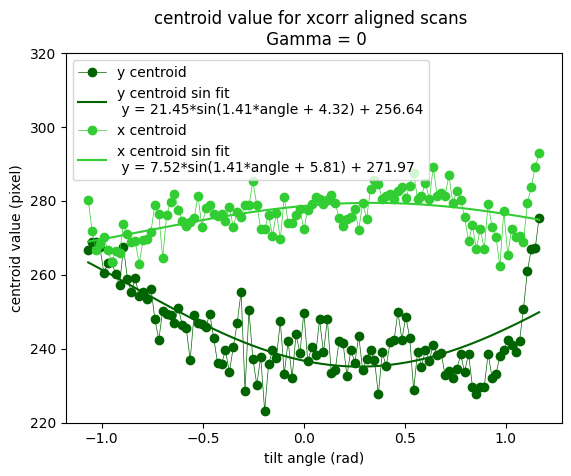

In [9]:
plot_angles = np.linspace(angle[0], np.max(angle), angle.shape[0])
print(plot_angles.shape)
print(np.array(x_centroid).shape)

plot_angles_rad = np.deg2rad(plot_angles)

def cos_fit(x, A, yo, phase): 
    # x = theta
    b_fix = np.pi/ np.ptp(x)
    return A*np.cos(b_fix*x+phase) + yo


bounds = ([0, 0, -2*np.pi], [np.inf, np.inf, 2*np.pi])
guess = [10, np.mean(x_centroid), 6]
print(np.mean(x_centroid))

x_cos_params, x_cos_cov = curve_fit(cos_fit, plot_angles_rad, x_centroid, p0=guess, bounds=bounds)
print(x_cos_params)
x_cos_fit_0 = cos_fit(plot_angles_rad, x_cos_params[0], x_cos_params[1], x_cos_params[2])
b_fix = np.pi/ np.ptp(plot_angles_rad) ## period  = 2pi/B


plt.plot(plot_angles_rad, y_centroid, color = color1, marker = 'o', linewidth = '0.5', label = 'y centroid')
plt.plot(plot_angles_rad, y_sin_fit_0, color = color1, label = f'y centroid sin fit \n y = {y_params[0]:.2f}*sin({b_fix:.2f}*angle + {y_params[2]:.2f}) + {y_params[1]:.2f}')
    # b_fix = np.pi/ np.ptp(x)
    # return A*np.sin(b_fix*x+phase) + yo
plt.plot(plot_angles_rad, x_centroid, color = color2, marker = 'o', linewidth = '0.5', label = 'x centroid')
plt.plot(plot_angles_rad, x_cos_fit_0, color = color2, label = f'x centroid sin fit \n y = {x_cos_params[0]:.2f}*sin({b_fix:.2f}*angle + {x_cos_params[2]:.2f}) + {x_cos_params[1]:.2f}')

plt.xlabel('tilt angle (rad)')
plt.ylabel('centroid value (pixel)')
plt.title(f'centroid value for xcorr aligned scans \n Gamma = {Gamma}')
plt.legend(loc = 'upper left')
plt.ylim(220, 320)
plt.show()

In [10]:
x_shift_cos = x_cos_fit_0 - x_centroid #shift x to mean value 
print(x_shift_cos.shape)
y_shift = y_sin_fit_0 - y_centroid
print(y_shift.shape)

aligned_images_CC_cosx = np.zeros_like(CC)
aligned_images_XMCD_cosx = np.zeros_like(CC)
for k in range(CC.shape[0]):
    aligned_images_CC_cosx[k] = ndimage.shift(CC[k], shift = (y_shift[k], x_shift_cos[k]), mode = 'constant', cval=np.nan, order=1)
    aligned_images_XMCD_cosx[k] = ndimage.shift(XMCD[k], shift = (y_shift[k], x_shift_cos[k]), mode = 'constant', cval=np.nan, order=1)
print(aligned_images_CC_cosx.shape)

(116,)
(116,)
(116, 514, 514)


In [11]:
y_centroid_aligned_cosx= []
x_centroid_aligned_cosx = []
for k in range(CC.shape[0]):
    points = find_fiducial_points((((aligned_images_CC_cosx[k]-2)*-1)),fiduc_num,verbose=False)
    tuple_set = set(tuple(row) for row in points)
    y1,x1 = calculate_centroid_points(tuple_set)
    
    y_centroid_aligned_cosx.append(y1)
    x_centroid_aligned_cosx.append(x1)

## Find centroid of the aligned alpha image (used for Gamma alignment)

In [12]:
y_centroid_aligned= []
x_centroid_aligned = []
for k in range(CC.shape[0]):
    points = find_fiducial_points((((aligned_images_CC[k]-2)*-1)),fiduc_num,verbose=False)
    tuple_set = set(tuple(row) for row in points)
    y1,x1 = calculate_centroid_points(tuple_set)
    
    y_centroid_aligned.append(y1)
    x_centroid_aligned.append(x1)

# Check alignment

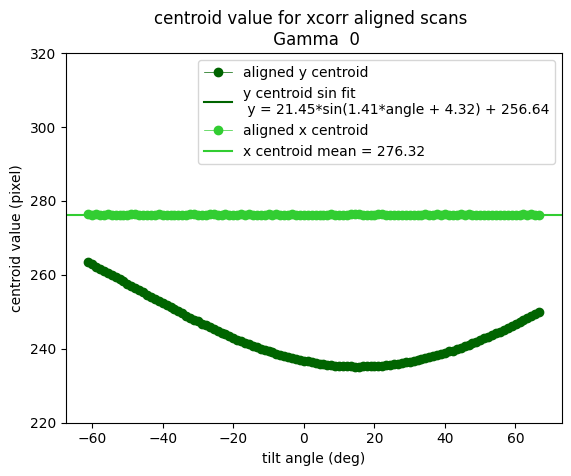

In [13]:
plt.plot(plot_angles, y_centroid_aligned, color = color1, marker = 'o', linewidth = '0.5', label = 'aligned y centroid')
plt.plot(plot_angles, y_sin_fit_0, color = color1, label = f'y centroid sin fit \n y = {y_params[0]:.2f}*sin({b_fix:.2f}*angle + {y_params[2]:.2f}) + {y_params[1]:.2f}')

plt.plot(plot_angles, x_centroid_aligned, color = color2, marker = 'o', linewidth = '0.5', label = 'aligned x centroid')
# plt.plot(plot_angles, x_lin_fit_0, color = color2, label = 'x centroid linear fit')
plt.axhline(mean_x_0, color = color2, label = f'x centroid mean = {mean_x_0:.2f}')


plt.xlabel('tilt angle (deg)')
plt.ylabel('centroid value (pixel)')
plt.title(f'centroid value for xcorr aligned scans \n Gamma  {Gamma}')
plt.legend()
plt.ylim(220, 320)
plt.show()

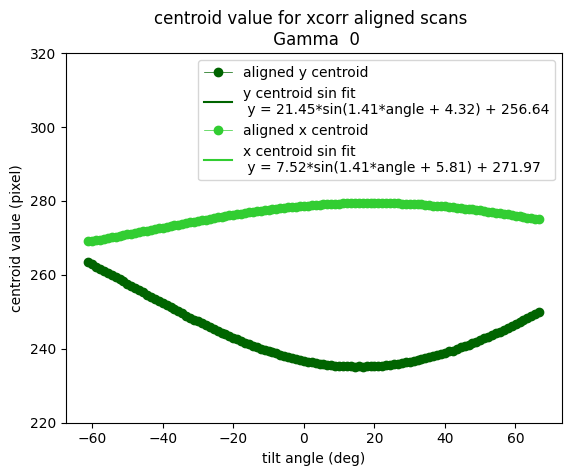

In [14]:
plt.plot(plot_angles, y_centroid_aligned_cosx, color = color1, marker = 'o', linewidth = '0.5', label = 'aligned y centroid')
plt.plot(plot_angles, y_sin_fit_0, color = color1, label = f'y centroid sin fit \n y = {y_params[0]:.2f}*sin({b_fix:.2f}*angle + {y_params[2]:.2f}) + {y_params[1]:.2f}')

plt.plot(plot_angles, x_centroid_aligned_cosx, color = color2, marker = 'o', linewidth = '0.5', label = 'aligned x centroid')
plt.plot(plot_angles, x_cos_fit_0, color = color2, label = f'x centroid sin fit \n y = {x_cos_params[0]:.2f}*sin({b_fix:.2f}*angle + {x_cos_params[2]:.2f}) + {x_cos_params[1]:.2f}')


plt.xlabel('tilt angle (deg)')
plt.ylabel('centroid value (pixel)')
plt.title(f'centroid value for xcorr aligned scans \n Gamma  {Gamma}')
plt.legend()
plt.ylim(220, 320)
plt.show()

In [15]:
stop

NameError: name 'stop' is not defined

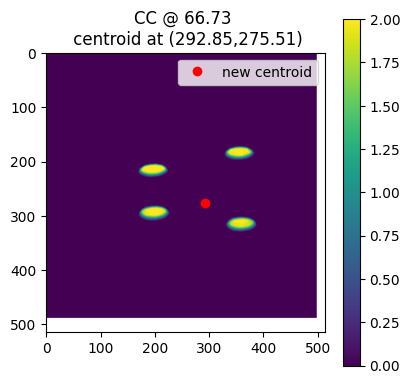

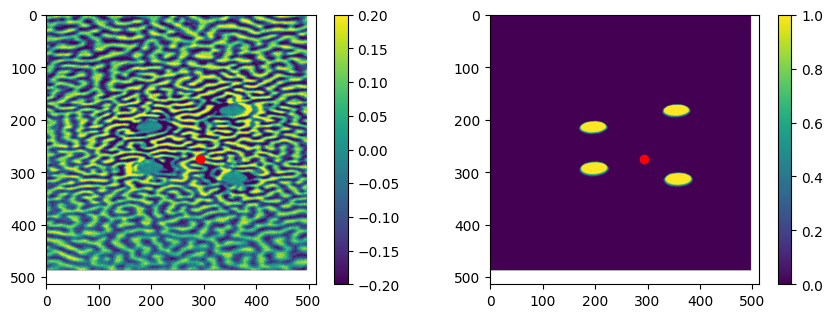

In [16]:
#Select image to look at first
CC = aligned_images_CC
XMCD = aligned_images_XMCD

CC_to_fit = (CC[k]-2)*-1
# Plot the images to see what each section looks like 
norm_CC = mpl.colors.Normalize(vmin=0, vmax=2)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
img = axes.imshow(CC_to_fit,cmap = 'viridis', norm=norm_CC)
axes.plot(x_centroid[k], y_centroid[k], 'ro', label = 'new centroid')
axes.set_title(f"CC @ {angle[k]:.2f} \n centroid at ({x_centroid[k]:.2f},{y_centroid[k]:.2f})") 
fig.colorbar(img)
axes.legend()
plt.show()

## Plot XMCD and CC of aligned images
norm = mpl.colors.Normalize(vmin=-0.2, vmax=0.2)
vmin = 0
vmax = 1
fig_size = 3.5
fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
XMCDimg = axes[0].imshow(XMCD[k], norm=norm)
axes[0].plot(x_centroid[k], y_centroid[k], 'ro', label = 'new centroid')
plt.colorbar(XMCDimg, ax = axes[0])
CCimg= axes[1].imshow((CC[k]-2)*-1, vmin = vmin, vmax = vmax) 
axes[1].plot(x_centroid[k], y_centroid[k], 'ro', label = 'new centroid')
plt.colorbar(CCimg, ax = axes[1])
plt.show()


In [ ]:
stop

# Save

In [ ]:
date

In [ ]:
# ## save aligned images
# tifffile.imwrite(os.path.join(data_dir, f"center_alpha_aligned_CC_sin{date}.tiff"), aligned_images_CC)
# tifffile.imwrite(os.path.join(data_dir, f"center_alpha_aligned_XMCD_sin{date}.tiff"), aligned_images_XMCD)

# np.savetxt(os.path.join(data_dir, f"center_y_centroid{date}.txt"), y_centroid)
# np.savetxt(os.path.join(data_dir, f"center_x_centroid{date}.txt"), x_centroid)

# np.savetxt(os.path.join(data_dir, f"center_y_sin_fit{date}.txt"), y_sin_fit_0)
# np.savetxt(os.path.join(data_dir, f"center_x_mean{date}.txt"), x_lin_fit_0)

# ## save aligned images with Cos x fit scheme
# tifffile.imwrite(os.path.join(data_dir_0, f"center_alpha_aligned_CC_siny_cosx{date}.tiff"), aligned_images_CC_cosx)
# tifffile.imwrite(os.path.join(data_dir_0, f"center_alpha_aligned_XMCD_siny_cosx{date}.tiff"), aligned_images_XMCD_cosx)

# np.savetxt(os.path.join(data_dir_0, f"center_y_centroid_siny_cosx{date}.txt"), y_centroid_aligned_cosx)
# np.savetxt(os.path.join(data_dir_0, f"center_x_centroid_siny_cosx{date}.txt"), x_centroid_aligned_cosx)

# np.savetxt(os.path.join(data_dir_0, f"center_y_sin_fit{date}.txt"), y_sin_fit_0)
# np.savetxt(os.path.join(data_dir_0, f"center_x_cos_fit{date}.txt"), x_cos_fit_0)

In [ ]:
# GAMMA -45 Fit Centroid!! 
    
plot_angles = np.linspace(angles_pospol_neg45[0], np.max(angles_pospol_neg45), angles_pospol_neg45.shape[0])
plot_angles_rad = np.deg2rad(plot_angles)
print(plot_angles_rad.shape)
print(y_centroid_neg45.shape)


bounds = ([0, 0, -2*np.pi], [np.inf, np.inf, 2*np.pi])
guess = [10, np.mean(y_centroid_neg45), 6]
print(np.mean(y_centroid_neg45))

y_params, y_cov = curve_fit(sin_fit, plot_angles_rad, y_centroid_neg45, p0=guess, bounds=bounds)
print(y_params)
y_sin_fit_neg45 = sin_fit(plot_angles_rad, y_params[0], y_params[1], y_params[2])

x_params, x_cov = curve_fit(lin_fit, plot_angles_rad, x_centroid_neg45, p0=[2,2])
print(x_params)
x_lin_fit_neg45 = lin_fit(plot_angles_rad, *x_params) 
print(f' x = {x_params[0]}*angle + {x_params[1]}')

residual = y_centroid_neg45 - sin_fit(plot_angles_rad, *y_params)
#plt.plot(plot_angles, residual, label = 'residual')

# reference points
mean_y_neg45 = np.mean(y_centroid_neg45) 
mean_x_neg45 = np.mean(x_centroid_neg45) 

## I think median will work better!!! 
median_y_neg45 = np.median(y_centroid_neg45) 
median_x_neg45 = np.median(x_centroid_neg45) 

plt.plot(plot_angles, y_centroid_neg45, color = 'orange', marker = 'o', linewidth = '0.5', label = 'y centroid')
plt.plot(plot_angles, y_sin_fit_neg45, color = 'orange', label = 'y centroid sin fit')
# plt.axhline(mean_y, color = 'blue', label = 'mean') 
# plt.axhline(median_y, color = 'red', label = 'median') 
plt.plot(plot_angles, x_centroid_neg45, color = 'blue', marker = 'o', linewidth = '0.5', label = 'x centroid')
plt.plot(plot_angles, x_lin_fit_neg45, color = 'blue', label = 'x centroid linear fit')
# plt.axhline(mean_x, color = 'blue', label = 'mean') 
# plt.axhline(median_x, color = 'red', label = 'median') 
plt.xlabel('tilt angle (deg)')
plt.ylabel('centroid value (pixel)')
plt.title(f'centroid value for xcorr aligned scans \n Gamma -45')
plt.legend()
plt.show()



In [ ]:
# GAMMA 0 Fit Centroid!! 
    
plot_angles = np.linspace(angles_pospol_0[0], np.max(angles_pospol_0), angles_pospol_0.shape[0])
plot_angles_rad = np.deg2rad(plot_angles)
print(plot_angles_rad.shape)
print(y_centroid_0.shape)


bounds = ([0, 0, -2*np.pi], [np.inf, np.inf, 2*np.pi])
guess = [10, np.mean(y_centroid_0), 6]
print(np.mean(y_centroid_0))

y_params, y_cov = curve_fit(sin_fit, plot_angles_rad, y_centroid_0, p0=guess, bounds=bounds)
print(y_params)
y_sin_fit_0 = sin_fit(plot_angles_rad, y_params[0], y_params[1], y_params[2])

x_params, x_cov = curve_fit(lin_fit, plot_angles_rad, x_centroid_0, p0=[2,2])
print(x_params)
x_lin_fit_0 = lin_fit(plot_angles_rad, *x_params) 
print(f' x = {x_params[0]}*angle + {x_params[1]}')

residual = y_centroid_0 - sin_fit(plot_angles_rad, *y_params)
#plt.plot(plot_angles, residual, label = 'residual')

# reference points
mean_y_0 = np.mean(y_centroid_0) 
mean_x_0 = np.mean(x_centroid_0) 

## I think median will work better!!! 
median_y_0 = np.median(y_centroid_0) 
median_x_0 = np.median(x_centroid_0) 

plt.plot(plot_angles, y_centroid_0, color = 'orange', marker = 'o', linewidth = '0.5', label = 'y centroid')
plt.plot(plot_angles, y_sin_fit_0, color = 'orange', label = 'y centroid sin fit')
# plt.axhline(mean_y, color = 'blue', label = 'mean') 
# plt.axhline(median_y, color = 'red', label = 'median') 
plt.plot(plot_angles, x_centroid_0, color = 'blue', marker = 'o', linewidth = '0.5', label = 'x centroid')
plt.plot(plot_angles, x_lin_fit_0, color = 'blue', label = 'x centroid linear fit')
# plt.axhline(mean_x, color = 'blue', label = 'mean') 
# plt.axhline(median_x, color = 'red', label = 'median') 
plt.xlabel('tilt angle (deg)')
plt.ylabel('centroid value (pixel)')
plt.title(f'centroid value for xcorr aligned scans \n Gamma 0')
plt.legend()
plt.show()


In [ ]:
# GAMMA 45 Fit Centroid!! 
    
plot_angles_pos45 = np.linspace(angles_pospol[0], np.max(angles_pospol), angles_pospol.shape[0])
plot_angles_rad_pos45 = np.deg2rad(plot_angles_pos45)
print(plot_angles_rad_pos45.shape)
print(y_centroid_pos45.shape)


bounds = ([0, 0, -2*np.pi], [np.inf, np.inf, 2*np.pi])
guess = [10, np.mean(y_centroid_pos45), 6]
print(np.mean(y_centroid_pos45))

y_params_pos45, y_cov = curve_fit(sin_fit, plot_angles_rad_pos45, y_centroid_pos45, p0=guess, bounds=bounds)
print(y_params)
y_sin_fit_pos45 = sin_fit(plot_angles_rad_pos45, y_params_pos45[0], y_params_pos45[1], y_params_pos45[2])

x_params_pos45, x_cov = curve_fit(lin_fit, plot_angles_rad_pos45, x_centroid_pos45, p0=[2,2])
print(x_params)
x_lin_fit_pos45 = lin_fit(plot_angles_rad_pos45, *x_params_pos45)

residual = y_centroid_pos45 - sin_fit(plot_angles_rad_pos45, *y_params_pos45)
#plt.plot(plot_angles, residual, label = 'residual')

# reference points
mean_y_pos45 = np.mean(y_centroid_pos45) 
mean_x_pos45 = np.mean(x_centroid_pos45) 

## I think median will work better!!! 
median_y_pos45 = np.median(y_centroid_pos45) 
median_x_pos45 = np.median(x_centroid_pos45) 

plt.plot(plot_angles_pos45, y_centroid_pos45, color = 'orange', marker = 'o', linewidth = '0.5', label = 'y centroid')
plt.plot(plot_angles_pos45, y_sin_fit_pos45, color = 'orange', label = 'y centroid sin fit')
# plt.axhline(mean_y, color = 'blue', label = 'mean') 
# plt.axhline(median_y, color = 'red', label = 'median') 
plt.plot(plot_angles_pos45, x_centroid_pos45, color = 'blue', marker = 'o', linewidth = '0.5', label = 'x centroid')
plt.plot(plot_angles_pos45, x_lin_fit_pos45, color = 'blue', label = 'x centroid linear fit')
# plt.axhline(mean_x, color = 'blue', label = 'mean') 
# plt.axhline(median_x, color = 'red', label = 'median') 
plt.xlabel('tilt angle (deg)')
plt.ylabel('centroid value (pixel)')
plt.title(f'centroid value for xcorr aligned scans \n Gamma +45')
plt.legend()
plt.show()

print(y_sin_fit_pos45[41] - y_centroid_pos45[41])

In [ ]:
#plot centroid
k=2
fiduc_num = 4
CC_to_fit = (image_CC[k]-2)*-1
y,x = calculate_centroid(CC_to_fit)
points = find_fiducial_points(CC_to_fit, fiduc_num, verbose=False)
#print(points)
tuple_set = set(tuple(row) for row in points)
#print(tuple_set)
y1,x1 = calculate_centroid_points(tuple_set)
print(f'(y,x) = {y1,x1}')
print(f' neg sin fit (y,x) = ({y_sin_fit_neg45[k],x_lin_fit_neg45[k]})')
print(f'pos sin fit (y,x) = ({y_sin_fit_pos45[k],x_lin_fit_pos45[k]})')
# Plot the images to see what each section looks like 
norm_CC = mpl.colors.Normalize(vmin=0, vmax=2)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
XMCD_OD = axes.imshow(CC_to_fit,cmap = 'viridis', norm=norm_CC)
#axes.plot(x, y, 'ko')
axes.plot(x1, y1, 'ro')
axes.plot(x_lin_fit_pos45[k], y_sin_fit_pos45[k], 'bo')
axes.plot(x_lin_fit_neg45[k], y_sin_fit_neg45[k], 'go')
axes.set_title(f"CC @ {angles_pospol[k]:.2f} \n centroid at ({x:.2f},{y:.2f})") 
fig.colorbar(XMCD_OD)
plt.show()



k=100
fiduc_num = 4
CC_to_fit_2 = (image_CC[k]-2)*-1
y,x = calculate_centroid(CC_to_fit_2)
points = find_fiducial_points(CC_to_fit_2, fiduc_num, verbose=False)
#print(points)
tuple_set = set(tuple(row) for row in points)
#print(tuple_set)
y2,x2 = calculate_centroid_points(tuple_set)
print(f'(y,x) = {y2,x2}')
print(f' neg sin fit (y,x) = ({y_sin_fit_neg45[k],x_lin_fit_neg45[k]})')
print(f'pos sin fit (y,x) = ({y_sin_fit_pos45[k],x_lin_fit_pos45[k]})')
# Plot the images to see what each section looks like 
norm_CC = mpl.colors.Normalize(vmin=0, vmax=2)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
XMCD_OD = axes.imshow(CC_to_fit_2,cmap = 'viridis', norm=norm_CC)
#axes.plot(x, y, 'ko')
axes.plot(x2, y2, 'ro')
axes.plot(x_lin_fit_pos45[k], y_sin_fit_pos45[k], 'bo')
axes.plot(x_lin_fit_neg45[k], y_sin_fit_neg45[k], 'go')
axes.set_title(f"CC @ {angles_pospol[k]:.2f} \n centroid at ({x:.2f},{y:.2f})") 
fig.colorbar(XMCD_OD)
plt.show()


#find a new b for the x shift, y shift will be ok I think
new_m = (y2-y1)/(x2-x1)
new_b1 = y1 - new_m*x1
new_b2 = y2 - new_m*x2
print(f'new_m = {new_m}')
print(f'new_b1 = {new_b1},new_b2 = {new_b2}, delta = {new_b1 - new_b2} ')
new_b = new_b1




In [ ]:
x_fit_pos45_params = [new_m, new_b]

k = 2
# Plot the images to see what each section looks like 
x_fit1 = x_fit_pos45_params[0]*angles_pospol[k]+x_fit_pos45_params[1]
norm_CC = mpl.colors.Normalize(vmin=0, vmax=2)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
XMCD_OD = axes.imshow(CC_to_fit,cmap = 'viridis', norm=norm_CC)
#axes.plot(x, y, 'ko')
axes.plot(x1, y1, 'ro')
axes.plot(x_lin_fit_pos45[k], y_sin_fit_pos45[k], 'bo')
axes.plot(x_lin_fit_neg45[k], y_sin_fit_pos45[k], 'go')
axes.plot(mean_x_pos45, y_sin_fit_pos45[k], 'wo')
axes.set_title(f"CC @ {angles_pospol[k]:.2f} \n centroid at ({x1:.2f},{y1:.2f})") 
fig.colorbar(XMCD_OD)
plt.show()


k = 3
# Plot the images to see what each section looks like 
x_fit2 = x_fit_pos45_params[0]*angles_pospol[k]+x_fit_pos45_params[1]
norm_CC = mpl.colors.Normalize(vmin=0, vmax=2)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
XMCD_OD = axes.imshow(CC_to_fit_2,cmap = 'viridis', norm=norm_CC)
#axes.plot(x, y, 'ko')
axes.plot(x2, y2, 'ro')
axes.plot(x_lin_fit_pos45[k], y_sin_fit_pos45[k], 'bo')
axes.plot(x_lin_fit_neg45[k], y_sin_fit_neg45[k], 'go')
axes.plot(mean_x_pos45, y_sin_fit_pos45[k], 'wo')
axes.set_title(f"CC @ {angles_pospol[k]:.2f} \n centroid at ({x2:.2f},{y2:.2f})") 
fig.colorbar(XMCD_OD)
plt.show()




In [ ]:
# Shift x to centroid 
#subtract
norm_CC = mpl.colors.Normalize(vmin=0, vmax=2)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
XMCD_OD = axes.imshow(CC_to_fit_2 - CC_to_fit  ,cmap = 'viridis', norm=norm_CC)
axes.plot(x1, y1, 'bo')
axes.plot(x2, y2, 'yo')
axes.plot(mean_x_pos45, y_sin_fit_pos45[2], 'wo')
#axes.plot(x, y, 'ko')
fig.colorbar(XMCD_OD)
axes.set_title(f"No shift") 
plt.show()

print('based on image shift k = 2 left')
x_shift1 = mean_x_pos45 - x1 #shift x to median value 
print(f'x_shift1 = {x_shift1}')
aligned_images_CC_1x = ndimage.shift(CC_to_fit, shift = (0, x_shift1), mode = 'constant')
# Calculate new y,x for aligned image
y,x = calculate_centroid(aligned_images_CC_1x)
points = find_fiducial_points(aligned_images_CC_1x, fiduc_num, verbose=False)
#print(points)
tuple_set = set(tuple(row) for row in points)
#print(tuple_set)
y1_new,x1_new = calculate_centroid_points(tuple_set)
# y_shift = y_sin_fit_pos45[k] - y_centroid_pos45[k]
# # print(x_shift) 
# # print(y_shift) 

## plot new and compare
norm_CC = mpl.colors.Normalize(vmin=0, vmax=2)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
XMCD_OD = axes.imshow(CC_to_fit_2 - aligned_images_CC_1x  ,cmap = 'viridis', norm=norm_CC)
axes.plot(x1, y1, 'bo')
axes.plot(x2, y2, 'yo')
axes.plot(mean_x_pos45, y_sin_fit_pos45[2], 'wo')
axes.plot(x1_new, y1_new, 'b^')
#axes.plot(x, y, 'ko')
fig.colorbar(XMCD_OD)
axes.set_title(f"shift x") 
plt.show()

# Shift y to centroid 
print('shift image k = 2 sligtly down!')
y_shift1= y_sin_fit_pos45[k] - y1 #shift y to 'fit' value
print(f'y_shift1 = {y_shift1}')
aligned_images_CC_1xy = ndimage.shift(aligned_images_CC_1x, shift = (y_shift1, 0), mode = 'constant')
# Calculate new y,x for aligned image
y,x = calculate_centroid(aligned_images_CC_1xy)
points = find_fiducial_points(aligned_images_CC_1xy, fiduc_num, verbose=False)
#print(points)
tuple_set = set(tuple(row) for row in points)
#print(tuple_set)
y1_newer,x1_newer = calculate_centroid_points(tuple_set)
## plot new and compare
norm_CC = mpl.colors.Normalize(vmin=0, vmax=2)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
XMCD_OD = axes.imshow(CC_to_fit_2 - aligned_images_CC_1xy  ,cmap = 'viridis', norm=norm_CC)
axes.plot(x1, y1, 'bo')
axes.plot(x2, y2, 'yo')
axes.plot(mean_x_pos45, y_sin_fit_pos45[2], 'wo')
axes.plot(x1_new, y1_new, 'b^')
axes.plot(x1_newer, y1_newer, 'bs')
#axes.plot(x, y, 'ko')
fig.colorbar(XMCD_OD)
axes.set_title(f"shift y") 
plt.show()

# Do it in one step 
print('shift image k x and y simultaneously')
y_shift= y_sin_fit_pos45[k] - y1 #shift y to 'fit' value
x_shift = mean_x_pos45 - x1 #shift x to median value 
print(f'y_shift = {y_shift}')
print(f'x_shift = {x_shift}')
aligned_images_CC_1_total = ndimage.shift(CC_to_fit, shift = (y_shift, x_shift), mode = 'constant')

y,x = calculate_centroid(aligned_images_CC_1_total)
points = find_fiducial_points(aligned_images_CC_1_total, fiduc_num, verbose=False)
#print(points)
tuple_set = set(tuple(row) for row in points)
#print(tuple_set)
y1_total,x1_total = calculate_centroid_points(tuple_set)

## plot new and compare
norm_CC = mpl.colors.Normalize(vmin=0, vmax=2)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
XMCD_OD = axes.imshow(CC_to_fit_2 - aligned_images_CC_1_total  ,cmap = 'viridis', norm=norm_CC)
axes.plot(x1, y1, 'bo')
axes.plot(x2, y2, 'yo')
axes.plot(mean_x_pos45, y_sin_fit_pos45[2], 'wo')
axes.plot(x1_new, y1_new, 'b^')
axes.plot(x1_newer, y1_newer, 'bs')
axes.plot(x1_total, y1_total, 'b*')
#axes.plot(x, y, 'ko')
fig.colorbar(XMCD_OD)
axes.set_title(f"shift x and y") 
plt.show()



In [ ]:
# shift in x
x_shift1 = mean_x_pos45 - x1 #shift x to median value 
y_shift = y_sin_fit_pos45[k] - y_centroid_pos45[k]
# print(x_shift) 
# print(y_shift) 

aligned_images_CC[k] = ndimage.shift(image_CC[k], shift = (y_shift, x_shift), mode = 'constant')
aligned_images_XMCD[k] = ndimage.shift(image_XMCD[k], shift = (y_shift, x_shift), mode = 'constant')

In [ ]:
# shift the x fit to a reasonable postion 
    
plot_angles = np.linspace(angles_pospol_neg45[0], np.max(angles_pospol_neg45), angles_pospol_neg45.shape[0])
plot_angles_rad = np.deg2rad(plot_angles)
print(plot_angles_rad.shape)
print(y_centroid_neg45.shape)


bounds = ([0, 0, -2*np.pi], [np.inf, np.inf, 2*np.pi])
guess = [10, np.mean(y_centroid_neg45), 6]
print(np.mean(y_centroid_neg45))

y_params, y_cov = curve_fit(sin_fit, plot_angles_rad, y_centroid_neg45, p0=guess, bounds=bounds)
print(y_params)
y_sin_fit_neg45 = sin_fit(plot_angles_rad, y_params[0], y_params[1], y_params[2])

x_params, x_cov = curve_fit(lin_fit, plot_angles_rad, x_centroid_neg45, p0=[2,2])
print(x_params)
x_lin_fit_neg45 = lin_fit(plot_angles_rad, *x_params)

residual = y_centroid_neg45 - sin_fit(plot_angles_rad, *y_params)
#plt.plot(plot_angles, residual, label = 'residual')

# reference points
mean_y_neg45 = np.mean(y_centroid_neg45) 
mean_x_neg45 = np.mean(x_centroid_neg45) 

## I think median will work better!!! 
median_y_neg45 = np.median(y_centroid_neg45) 
median_x_neg45 = np.median(x_centroid_neg45) 

plt.plot(plot_angles, y_centroid_neg45, color = 'orange', marker = 'o', linewidth = '0.5', label = 'y centroid')
plt.plot(plot_angles, y_sin_fit_neg45, color = 'orange', label = 'y centroid sin fit')
# plt.axhline(mean_y, color = 'blue', label = 'mean') 
# plt.axhline(median_y, color = 'red', label = 'median') 
plt.plot(plot_angles, x_centroid_neg45, color = 'blue', marker = 'o', linewidth = '0.5', label = 'x centroid')
plt.plot(plot_angles, x_lin_fit_neg45, color = 'blue', label = 'x centroid linear fit')
# plt.axhline(mean_x, color = 'blue', label = 'mean') 
# plt.axhline(median_x, color = 'red', label = 'median') 
plt.xlabel('tilt angle (deg)')
plt.ylabel('centroid value (pixel)')
plt.title(f'centroid value for xcorr aligned scans \n Gamma -45')
plt.legend()
plt.show()


In [ ]:
### Try this for central number


k = 24
CC_to_fit = (image_CC[k]-2)*-1

y,x = calculate_centroid(CC_to_fit)
points = find_fiducial_points(CC_to_fit, fiduc_num, verbose=False)
#print(points)
tuple_set = set(tuple(row) for row in points)
#print(tuple_set)
y1,x1 = calculate_centroid_points(tuple_set)

# Plot the images to see what each section looks like 
x_fit1 = x_fit_pos45_params[0]*angles_pospol[k]+x_fit_pos45_params[1]
norm_CC = mpl.colors.Normalize(vmin=0, vmax=2)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
XMCD_OD = axes.imshow(CC_to_fit,cmap = 'viridis', norm=norm_CC)
#axes.plot(x, y, 'ko')
axes.plot(x1, y1, 'ro')
axes.plot(mean_x_pos45, y_sin_fit_pos45[k], 'wo')
axes.set_title(f"CC @ {angles_pospol[k]:.2f} \n centroid at ({x1:.2f},{y1:.2f})") 
fig.colorbar(XMCD_OD)
plt.show()


k = 25
CC_to_fit_2 = (image_CC[k]-2)*-1

y,x = calculate_centroid(CC_to_fit_2)
points = find_fiducial_points(CC_to_fit_2, fiduc_num, verbose=False)
#print(points)
tuple_set = set(tuple(row) for row in points)
#print(tuple_set)
y2,x2 = calculate_centroid_points(tuple_set)

# Plot the images to see what each section looks like 
x_fit2 = x_fit_pos45_params[0]*angles_pospol[k]+x_fit_pos45_params[1]
norm_CC = mpl.colors.Normalize(vmin=0, vmax=2)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
XMCD_OD = axes.imshow(CC_to_fit_2,cmap = 'viridis', norm=norm_CC)
#axes.plot(x, y, 'ko')
axes.plot(x2, y2, 'ro')
axes.plot(mean_x_pos45, y_sin_fit_pos45[k], 'wo')
axes.set_title(f"CC @ {angles_pospol[k]:.2f} \n centroid at ({x2:.2f},{y2:.2f})") 
fig.colorbar(XMCD_OD)
plt.show()


######################################################################################################################################################

#Shift x to centroid 
#subtract
norm_CC = mpl.colors.Normalize(vmin=-2, vmax=2)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
XMCD_OD = axes.imshow(CC_to_fit_2 - CC_to_fit  ,cmap = 'viridis', norm=norm_CC)
axes.plot(x1, y1, 'bo')
axes.plot(x2, y2, 'yo')
axes.plot(mean_x_pos45, y_sin_fit_pos45[k-1], 'wo')
#axes.plot(x, y, 'ko')
fig.colorbar(XMCD_OD)
axes.set_title(f"No shift") 
plt.show()

print('based on image shift k = 2 left')
x_shift1 = mean_x_pos45 - x1 #shift x to median value 
print(f'x_shift1 = {x_shift1}')
aligned_images_CC_1x = ndimage.shift(CC_to_fit, shift = (0, x_shift1), mode = 'constant')
# Calculate new y,x for aligned image
y,x = calculate_centroid(aligned_images_CC_1x)
points = find_fiducial_points(aligned_images_CC_1x, fiduc_num, verbose=False)
tuple_set = set(tuple(row) for row in points)
y1_new,x1_new = calculate_centroid_points(tuple_set)

## plot new and compare
norm_CC = mpl.colors.Normalize(vmin=-2, vmax=2)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
XMCD_OD = axes.imshow(CC_to_fit_2 - aligned_images_CC_1x  ,cmap = 'viridis', norm=norm_CC)
axes.plot(x1, y1, 'bo')
axes.plot(x2, y2, 'yo')
axes.plot(mean_x_pos45, y_sin_fit_pos45[k-1], 'wo')
axes.plot(x1_new, y1_new, 'b^')
#axes.plot(x, y, 'ko')
fig.colorbar(XMCD_OD)
axes.set_title(f"shift x") 
plt.show()

# Shift y to centroid 
print('shift image k = 2 sligtly down!')
y_shift1= y_sin_fit_pos45[k] - y1 #shift y to 'fit' value
print(f'y_shift1 = {y_shift1}')
aligned_images_CC_1xy = ndimage.shift(aligned_images_CC_1x, shift = (y_shift1, 0), mode = 'constant')
# Calculate new y,x for aligned image
y,x = calculate_centroid(aligned_images_CC_1xy)
points = find_fiducial_points(aligned_images_CC_1xy, fiduc_num, verbose=False)
#print(points)
tuple_set = set(tuple(row) for row in points)
#print(tuple_set)
y1_newer,x1_newer = calculate_centroid_points(tuple_set)
## plot new and compare
norm_CC = mpl.colors.Normalize(vmin=-2, vmax=2)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
XMCD_OD = axes.imshow(CC_to_fit_2 - aligned_images_CC_1xy  ,cmap = 'viridis', norm=norm_CC)
axes.plot(x1, y1, 'bo')
axes.plot(x2, y2, 'yo')
axes.plot(mean_x_pos45, y_sin_fit_pos45[k-1], 'wo')
axes.plot(x1_new, y1_new, 'b^')
axes.plot(x1_newer, y1_newer, 'bs')
#axes.plot(x, y, 'ko')
fig.colorbar(XMCD_OD)
axes.set_title(f"shift y") 
plt.show()

# Do it in one step 
print('shift image k x and y simultaneously')
y_shift= y_sin_fit_pos45[k] - y1 #shift y to 'fit' value
x_shift = mean_x_pos45 - x1 #shift x to median value 
print(f'y_shift = {y_shift}')
print(f'x_shift = {x_shift}')
aligned_images_CC_1_total = ndimage.shift(CC_to_fit, shift = (y_shift, x_shift), mode = 'constant')

y,x = calculate_centroid(aligned_images_CC_1_total)
points = find_fiducial_points(aligned_images_CC_1_total, fiduc_num, verbose=False)
#print(points)
tuple_set = set(tuple(row) for row in points)
#print(tuple_set)
y1_total,x1_total = calculate_centroid_points(tuple_set)

## plot new and compare
norm_CC = mpl.colors.Normalize(vmin=-2, vmax=2)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
XMCD_OD = axes.imshow(CC_to_fit_2 - aligned_images_CC_1_total  ,cmap = 'viridis', norm=norm_CC)
axes.plot(x1, y1, 'bo')
axes.plot(x2, y2, 'yo')
axes.plot(mean_x_pos45, y_sin_fit_pos45[k-1], 'wo')
axes.plot(x1_new, y1_new, 'b^')
axes.plot(x1_newer, y1_newer, 'bs')
axes.plot(x1_total, y1_total, 'b*')
#axes.plot(x, y, 'ko')
fig.colorbar(XMCD_OD)
axes.set_title(f"shift x and y") 
plt.show()


## plot new and compare
norm_CC = mpl.colors.Normalize(vmin=-2, vmax=2)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
XMCD_OD = axes.imshow(CC_to_fit - aligned_images_CC_1_total  ,cmap = 'viridis', norm=norm_CC)
axes.plot(x1, y1, 'bo')
axes.plot(x2, y2, 'yo')
axes.plot(mean_x_pos45, y_sin_fit_pos45[k-1], 'wo')
axes.plot(x1_new, y1_new, 'b^')
axes.plot(x1_newer, y1_newer, 'bs')
axes.plot(x1_total, y1_total, 'b*')
#axes.plot(x, y, 'ko')
fig.colorbar(XMCD_OD)
axes.set_title(f"Does this shift actually work?") 
plt.show()


In [ ]:
### Try shifting both 

angles = [24,25]
save_centroid_y_again = []
save_centroid_x_again = []
aligned_CC = np.zeros_like(image_CC)

for k in angles: 
    CC_to_fit = (image_CC[k]-2)*-1

    y,x = calculate_centroid(CC_to_fit)
    points = find_fiducial_points(CC_to_fit, fiduc_num, verbose=False)
    #print(points)
    tuple_set = set(tuple(row) for row in points)
    #print(tuple_set)
    y1,x1 = calculate_centroid_points(tuple_set)
    save_centroid_y_again.append(y1)
    save_centroid_x_again.append(x1)

    # Plot the images to see what each section looks like 
    norm_CC = mpl.colors.Normalize(vmin=-1, vmax=1)
    fig_size = 4.5
    fig, axes = plt.subplots(figsize=(fig_size, fig_size))
    XMCD_OD = axes.imshow(CC_to_fit, cmap = 'viridis', norm=norm_CC)
    axes.plot(x1, y1, 'ro', label = 'current centroid')
    axes.plot(mean_x_pos45, y_sin_fit_pos45[k], 'wo', label = 'goal centroid')
    axes.set_title(f"CC @ {angles_pospol[k]:.2f} \n centroid at ({x1:.2f},{y1:.2f})") 
    axes.legend()
    fig.colorbar(XMCD_OD)
    plt.show()

###################  Shift x and y to goal centroid #################################################

    y_shift= y_sin_fit_pos45[k] - y1 #shift y to 'fit' value
    x_shift = mean_x_pos45 - x1 #shift x to median value 
    print(f'y_shift = {y_shift}')
    print(f'x_shift = {x_shift}')
    aligned_images_CC_1_total = ndimage.shift(CC_to_fit, shift = (y_shift, x_shift), mode = 'constant')
    aligned_CC[k] = aligned_images_CC_1_total
###################  Find centroid of algined image #################################################

    y,x = calculate_centroid(aligned_images_CC_1_total)
    points = find_fiducial_points(aligned_images_CC_1_total, fiduc_num, verbose=False)
    #print(points)
    tuple_set = set(tuple(row) for row in points)
    #print(tuple_set)
    y1_total,x1_total = calculate_centroid_points(tuple_set)

###################  plot new aligned with centroids #################################################

    norm_CC = mpl.colors.Normalize(vmin=-2, vmax=2)
    fig_size = 4.5
    fig, axes = plt.subplots(figsize=(fig_size, fig_size))
    XMCD_OD = axes.imshow(aligned_images_CC_1_total  ,cmap = 'viridis', norm=norm_CC)
    axes.plot(mean_x_pos45, y_sin_fit_pos45[k], 'wo', label = 'goal centroid')
    axes.plot(x1_total, y1_total, 'r*', label = 'algined centroid')
    fig.colorbar(XMCD_OD)
    axes.set_title(f"Aligned image @ {angles_pospol[k]:.2f} ") 
    plt.show()
    
    ## plot new and compare
    norm_CC = mpl.colors.Normalize(vmin=-2, vmax=2)
    fig_size = 4.5
    fig, axes = plt.subplots(figsize=(fig_size, fig_size))
    XMCD_OD = axes.imshow(CC_to_fit - aligned_images_CC_1_total  ,cmap = 'viridis', norm=norm_CC)
    axes.plot(mean_x_pos45, y_sin_fit_pos45[k], 'wo', label = 'goal centroid')
    axes.plot(x1_total, y1_total, 'r*', label = 'algined centroid')
    fig.colorbar(XMCD_OD)
    axes.set_title(f"Does this shift actually work?") 
    plt.show()




##### plot algined neighbors to check ###################################

norm_CC = mpl.colors.Normalize(vmin=-2, vmax=2)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
XMCD_OD = axes.imshow((((image_CC[angles[1]]-2)*-1) - (image_CC[angles[0]]-2)*-1)  ,cmap = 'viridis', norm=norm_CC)
axes.plot(mean_x_pos45, y_sin_fit_pos45[k], 'wo', label = 'goal centroid')
axes.plot(x1_total, y1_total, 'r*', label = 'algined centroid')
fig.colorbar(XMCD_OD)
axes.set_title(f"Unaligned neighbors \n @ {angles_pospol[angles[1]]:.2f} and {angles_pospol[angles[0]]:.2f}") 
plt.show()

## plot new and compare
norm_CC = mpl.colors.Normalize(vmin=-0.5, vmax=0.5)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
XMCD_OD = axes.imshow(aligned_CC[1] - aligned_CC[0],cmap = 'viridis', norm=norm_CC)
axes.plot(mean_x_pos45, y_sin_fit_pos45[k], 'wo', label = 'goal centroid')
axes.plot(x1_total, y1_total, 'r*', label = 'algined centroid')
fig.colorbar(XMCD_OD)
axes.set_title(f"Aligned neighbors \n @ {angles_pospol[k]:.2f} and {angles_pospol[k+1]:.2f}") 
plt.show()





## Shift all to centroid

In [ ]:
### Try shifting all
fiduc_num = 4

if Gamma == "Gammaneg45": 
    x_mean = mean_x_neg45
    y_sin_fit = y_sin_fit_neg45

elif Gamma == "Gamma0": 
    x_mean = mean_x_0
    y_sin_fit = y_sin_fit_0

save_centroid_y_again = []
save_centroid_x_again = []
aligned_CC = np.zeros_like(image_CC)
aligned_XMCD = np.zeros_like(image_CC)

for k in range(image_CC.shape[0]): 
    #print(f'================================================= {angles_pospol[k]:.2f} =================================================')
    CC_to_fit = (image_CC[k]-2)*-1

    y,x = calculate_centroid(CC_to_fit)
    points = find_fiducial_points(CC_to_fit, fiduc_num, verbose=False)
    #print(points)
    tuple_set = set(tuple(row) for row in points)
    #print(tuple_set)
    y1,x1 = calculate_centroid_points(tuple_set)
    save_centroid_y_again.append(y1)
    save_centroid_x_again.append(x1)

    # # Plot the images to see what each section looks like 
    # norm_CC = mpl.colors.Normalize(vmin=-1, vmax=1)
    # fig_size = 4.5
    # fig, axes = plt.subplots(figsize=(fig_size, fig_size))
    # XMCD_OD = axes.imshow(CC_to_fit, cmap = 'viridis', norm=norm_CC)
    # axes.plot(x1, y1, 'ro', label = 'current centroid')
    # axes.plot(x_mean, y_sin_fit[k], 'wo', label = 'goal centroid')
    # axes.set_title(f"CC @ {angles_pospol[k]:.2f}, {Gamma} \n centroid at ({x1:.2f},{y1:.2f})") 
    # axes.legend()
    # fig.colorbar(XMCD_OD)
    # plt.show()

# ###################  Shift x and y to goal centroid #################################################

#     y_shift= y_sin_fit[k] - y1 #shift y to 'fit' value
#     x_shift = x_mean - x1 #shift x to median value 
#     print(f'y_shift = {y_shift}')
#     print(f'x_shift = {x_shift}')
#     aligned_images_CC_1_total = ndimage.shift(CC_to_fit, shift = (y_shift, x_shift), mode = 'constant')
#     aligned_CC[k] = aligned_images_CC_1_total
#     aligned_XMCD[k] = ndimage.shift(image_XMCD[k], shift = (y_shift, x_shift), mode = 'constant')
    
# ###################  Find centroid of algined image #################################################

#     y,x = calculate_centroid(aligned_images_CC_1_total)
#     points = find_fiducial_points(aligned_images_CC_1_total, fiduc_num, verbose=False)
#     #print(points)
#     tuple_set = set(tuple(row) for row in points)
#     #print(tuple_set)
#     y1_total,x1_total = calculate_centroid_points(tuple_set)

# ###################  plot new aligned with centroids #################################################

#     norm_CC = mpl.colors.Normalize(vmin=-2, vmax=2)
#     fig_size = 4.5
#     fig, axes = plt.subplots(figsize=(fig_size, fig_size))
#     XMCD_OD = axes.imshow(aligned_images_CC_1_total  ,cmap = 'viridis', norm=norm_CC)
#     axes.plot(x_mean, y_sin_fit[k], 'wo', label = 'goal centroid')
#     axes.plot(x1_total, y1_total, 'r*', label = 'algined centroid')
#     fig.colorbar(XMCD_OD)
#     axes.set_title(f"Aligned image @ {angles_pospol[k]:.2f} \n {Gamma}") 
#     plt.show()
    
#     ## plot new and compare
#     norm_CC = mpl.colors.Normalize(vmin=-2, vmax=2)
#     fig_size = 4.5
#     fig, axes = plt.subplots(figsize=(fig_size, fig_size))
#     XMCD_OD = axes.imshow(CC_to_fit - aligned_images_CC_1_total  ,cmap = 'viridis', norm=norm_CC)
#     axes.plot(x_mean, y_sin_fit[k], 'wo', label = 'goal centroid')
#     axes.plot(x1_total, y1_total, 'r*', label = 'algined centroid')
#     fig.colorbar(XMCD_OD)
#     axes.set_title(f"Does this shift actually work?") 
#     plt.show()



In [ ]:
if Gamma == "Gammaneg45": 
# GAMMA -45 Fit Centroid!! 
    
    plot_angles = np.linspace(angles_pospol_neg45[0], np.max(angles_pospol_neg45), angles_pospol_neg45.shape[0])
    plot_angles_rad = np.deg2rad(plot_angles)
    print(plot_angles_rad.shape)
    print(y_centroid_neg45.shape)
    
    
    bounds = ([0, 0, -2*np.pi], [np.inf, np.inf, 2*np.pi])
    guess = [10, np.mean(y_centroid_neg45), 6]
    print(np.mean(y_centroid_neg45))
    
    y_params, y_cov = curve_fit(sin_fit, plot_angles_rad, save_centroid_y_again, p0=guess, bounds=bounds)
    print(y_params)
    y_sin_fit_neg45 = sin_fit(plot_angles_rad, y_params[0], y_params[1], y_params[2])
    
    x_params, x_cov = curve_fit(lin_fit, plot_angles_rad, save_centroid_x_again, p0=[2,2])
    print(x_params)
    x_lin_fit_neg45 = lin_fit(plot_angles_rad, *x_params) 
    print(f' x = {x_params[0]}*angle + {x_params[1]}')
    
    residual = y_centroid_neg45 - sin_fit(plot_angles_rad, *y_params)
    #plt.plot(plot_angles, residual, label = 'residual')
    
    # reference points
    mean_y_neg45 = np.mean(save_centroid_y_again) 
    mean_x_neg45 = np.mean(save_centroid_x_again) 
    
    ## I think median will work better!!! 
    median_y_neg45 = np.median(save_centroid_y_again) 
    median_x_neg45 = np.median(save_centroid_x_again) 
    
    plt.plot(plot_angles, save_centroid_y_again, color = 'orange', marker = 'o', linewidth = '0.5', label = 'y centroid')
    plt.plot(plot_angles, y_sin_fit_neg45, color = 'orange', label = 'y centroid sin fit')
    # plt.axhline(mean_y, color = 'blue', label = 'mean') 
    # plt.axhline(median_y, color = 'red', label = 'median') 
    plt.plot(plot_angles, save_centroid_x_again, color = 'blue', marker = 'o', linewidth = '0.5', label = 'x centroid')
    # plt.plot(plot_angles, x_lin_fit_neg45, color = 'blue', label = 'x centroid linear fit')
    plt.axhline(mean_x_neg45, color = 'blue', label = 'mean') 
    # plt.axhline(median_x, color = 'red', label = 'median') 
    plt.xlabel('tilt angle (deg)')
    plt.ylabel('centroid value (pixel)')
    plt.title(f'centroid value for xcorr aligned scans \n Gamma -45')
    plt.legend()
    plt.show()

elif Gamma == "Gamma0":

    # GAMMA 0 Fit Centroid!! 
        
    plot_angles = np.linspace(angles_pospol_0[0], np.max(angles_pospol_0), angles_pospol_0.shape[0])
    plot_angles_rad = np.deg2rad(plot_angles)
    print(plot_angles_rad.shape)
    print(y_centroid_0.shape)
    
    
    bounds = ([0, 0, -2*np.pi], [np.inf, np.inf, 2*np.pi])
    guess = [10, np.mean(y_centroid_0), 6]
    print(np.mean(y_centroid_0))
    
    y_params, y_cov = curve_fit(sin_fit, plot_angles_rad, y_centroid_0, p0=guess, bounds=bounds)
    print(y_params)
    y_sin_fit_0 = sin_fit(plot_angles_rad, y_params[0], y_params[1], y_params[2])
    
    x_params, x_cov = curve_fit(lin_fit, plot_angles_rad, x_centroid_0, p0=[2,2])
    print(x_params)
    x_lin_fit_0 = lin_fit(plot_angles_rad, *x_params) 
    print(f' x = {x_params[0]}*angle + {x_params[1]}')
    
    residual = y_centroid_0 - sin_fit(plot_angles_rad, *y_params)
    #plt.plot(plot_angles, residual, label = 'residual')
    
    # reference points
    mean_y_0 = np.mean(y_centroid_0) 
    mean_x_0 = np.mean(x_centroid_0) 
    
    ## I think median will work better!!! 
    median_y_0 = np.median(y_centroid_0) 
    median_x_0 = np.median(x_centroid_0) 
    
    plt.plot(plot_angles, y_centroid_0, color = 'orange', marker = 'o', linewidth = '0.5', label = 'y centroid')
    plt.plot(plot_angles, y_sin_fit_0, color = 'orange', label = 'y centroid sin fit')
    # plt.axhline(mean_y, color = 'blue', label = 'mean') 
    # plt.axhline(median_y, color = 'red', label = 'median') 
    plt.plot(plot_angles, x_centroid_0, color = 'blue', marker = 'o', linewidth = '0.5', label = 'x centroid')
    plt.plot(plot_angles, x_lin_fit_0, color = 'blue', label = 'x centroid linear fit')
    # plt.axhline(mean_x, color = 'blue', label = 'mean') 
    # plt.axhline(median_x, color = 'red', label = 'median') 
    plt.xlabel('tilt angle (deg)')
    plt.ylabel('centroid value (pixel)')
    plt.title(f'centroid value for xcorr aligned scans \n Gamma 0')
    plt.legend()
    plt.show()

In [ ]:
### Try shifting all
fiduc_num = 4

if Gamma == "Gammaneg45": 
    x_mean = mean_x_neg45
    y_sin_fit = y_sin_fit_neg45

elif Gamma == "Gamma0": 
    x_mean = mean_x_0
    y_sin_fit = y_sin_fit_0

save_centroid_y_again = []
save_centroid_x_again = []
aligned_CC = np.zeros_like(image_CC)
aligned_XMCD = np.zeros_like(image_CC)

for k in range(image_CC.shape[0]): 
    print(f'================================================= {angles_pospol[k]:.2f} =================================================')
    CC_to_fit = (image_CC[k]-2)*-1

    y,x = calculate_centroid(CC_to_fit)
    points = find_fiducial_points(CC_to_fit, fiduc_num, verbose=False)
    #print(points)
    tuple_set = set(tuple(row) for row in points)
    #print(tuple_set)
    y1,x1 = calculate_centroid_points(tuple_set)
    save_centroid_y_again.append(y1)
    save_centroid_x_again.append(x1)

    # # Plot the images to see what each section looks like 
    # norm_CC = mpl.colors.Normalize(vmin=-1, vmax=1)
    # fig_size = 4.5
    # fig, axes = plt.subplots(figsize=(fig_size, fig_size))
    # XMCD_OD = axes.imshow(CC_to_fit, cmap = 'viridis', norm=norm_CC)
    # axes.plot(x1, y1, 'ro', label = 'current centroid')
    # axes.plot(x_mean, y_sin_fit[k], 'wo', label = 'goal centroid')
    # axes.set_title(f"CC @ {angles_pospol[k]:.2f}, {Gamma} \n centroid at ({x1:.2f},{y1:.2f})") 
    # axes.legend()
    # fig.colorbar(XMCD_OD)
    # plt.show()

###################  Shift x and y to goal centroid #################################################

    y_shift= y_sin_fit[k] - y1 #shift y to 'fit' value
    x_shift = x_mean - x1 #shift x to median value 
    print(f'y_shift = {y_shift}')
    print(f'x_shift = {x_shift}')
    aligned_images_CC_1_total = ndimage.shift(CC_to_fit, shift = (y_shift, x_shift), mode = 'constant')
    aligned_CC[k] = aligned_images_CC_1_total
    aligned_XMCD[k] = ndimage.shift(image_XMCD[k], shift = (y_shift, x_shift), mode = 'constant')
    
###################  Find centroid of algined image #################################################

    y,x = calculate_centroid(aligned_images_CC_1_total)
    points = find_fiducial_points(aligned_images_CC_1_total, fiduc_num, verbose=False)
    #print(points)
    tuple_set = set(tuple(row) for row in points)
    #print(tuple_set)
    y1_total,x1_total = calculate_centroid_points(tuple_set)

###################  plot new aligned with centroids #################################################

    norm_CC = mpl.colors.Normalize(vmin=-2, vmax=2)
    fig_size = 4.5
    fig, axes = plt.subplots(figsize=(fig_size, fig_size))
    XMCD_OD = axes.imshow(aligned_images_CC_1_total  ,cmap = 'viridis', norm=norm_CC)
    axes.plot(x_mean, y_sin_fit[k], 'wo', label = 'goal centroid')
    axes.plot(x1_total, y1_total, 'r*', label = 'algined centroid')
    fig.colorbar(XMCD_OD)
    axes.set_title(f"Aligned image @ {angles_pospol[k]:.2f} \n {Gamma}") 
    plt.show()
    
    ## plot new and compare
    norm_CC = mpl.colors.Normalize(vmin=-2, vmax=2)
    fig_size = 4.5
    fig, axes = plt.subplots(figsize=(fig_size, fig_size))
    XMCD_OD = axes.imshow(CC_to_fit - aligned_images_CC_1_total  ,cmap = 'viridis', norm=norm_CC)
    axes.plot(x_mean, y_sin_fit[k], 'wo', label = 'goal centroid')
    axes.plot(x1_total, y1_total, 'r*', label = 'algined centroid')
    fig.colorbar(XMCD_OD)
    axes.set_title(f"Does this shift actually work?") 
    plt.show()



In [ ]:
stop

In [ ]:
x_mean_array = np.array([x_mean])
print(x_mean_array)

In [ ]:
tifffile.imwrite(os.path.join(data_dir, f"center_alpha_aligned_CC_sin{date}.tiff"), aligned_CC)
tifffile.imwrite(os.path.join(data_dir, f"center_alpha_aligned_XMCD_sin{date}.tiff"), aligned_XMCD)

np.savetxt(os.path.join(data_dir, f"center_y_centroid{date}.txt"), save_centroid_y_again)
np.savetxt(os.path.join(data_dir, f"center_x_centroid{date}.txt"), save_centroid_x_again)

np.savetxt(os.path.join(data_dir, f"center_y_sin_fit{date}.txt"), y_sin_fit)
np.savetxt(os.path.join(data_dir, f"center_x_mean{date}.txt"), x_mean_array)

In [ ]:
stop

In [ ]:

##### plot algined neighbors to check ###################################
for k in range(image_CC.shape[0]): 
    # norm_CC = mpl.colors.Normalize(vmin=-2, vmax=2)
    # fig_size = 4.5
    # fig, axes = plt.subplots(figsize=(fig_size, fig_size))
    # XMCD_OD = axes.imshow((((image_CC[angles[1]]-2)*-1) - (image_CC[angles[0]]-2)*-1)  ,cmap = 'viridis', norm=norm_CC)
    # axes.plot(mean_x_pos45, y_sin_fit_pos45[k], 'wo', label = 'goal centroid')
    # axes.plot(x1_total, y1_total, 'r*', label = 'algined centroid')
    # fig.colorbar(XMCD_OD)
    # axes.set_title(f"Unaligned neighbors \n @ {angles_pospol[angles[1]]:.2f} and {angles_pospol[angles[0]]:.2f}") 
    # plt.show()
    
    ## plot new and compare
    norm_CC = mpl.colors.Normalize(vmin=-0.5, vmax=0.5)
    fig_size = 4.5
    fig, axes = plt.subplots(figsize=(fig_size, fig_size))
    XMCD_OD = axes.imshow(aligned_CC[k+1] - aligned_CC[k],cmap = 'viridis', norm=norm_CC)
    # axes.plot(mean_x_pos45, y_sin_fit_pos45[k], 'wo', label = 'goal centroid')
    # axes.plot(x1_total, y1_total, 'r*', label = 'algined centroid')
    fig.colorbar(XMCD_OD)
    axes.set_title(f"Aligned neighbors \n @ {angles_pospol[k+1]:.2f} and {angles_pospol[k+1]:.2f}") 
    plt.show()

In [ ]:
tifffile.imwrite(os.path.join(data_dir, f"alpha_aligned_CC_sin{date}.tiff"), aligned_CC)
tifffile.imwrite(os.path.join(data_dir, f"alpha_aligned_XMCD_sin{date}.tiff"), aligned_XMCD)


In [ ]:
## FOR GAMMApos45
aligned_images_CC = np.zeros_like(image_CC)
aligned_images_XMCD = np.zeros_like(image_CC)


for k in range(image_CC.shape[0]):
# for k in range(20):
    x_shift = mean_x_pos45 - x_centroid_pos45[k] #shift x to median value 
    y_shift = y_sin_fit_pos45[k] - y_centroid_pos45[k]
    # print(x_shift) 
    # print(y_shift) 

    aligned_images_CC[k] = ndimage.shift(image_CC[k], shift = (y_shift, x_shift), mode = 'constant')
    aligned_images_XMCD[k] = ndimage.shift(image_XMCD[k], shift = (y_shift, x_shift), mode = 'constant')
    
    # # Plot
    # fig_size = 3.5
    # fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
    # norm_diff = mpl.colors.Normalize(vmin=-1, vmax=1)
    # left = axes[0].imshow(image_CC[k],cmap = 'viridis', norm=norm_diff)
    # axes[0].set_title(f"Original image ({angles_pospol[k]:.2f})") 
    # axes[0].plot(mean_x_pos45, mean_y_pos45, 'bo')
    # axes[0].plot(median_x_pos45, median_y_pos45, 'ro')
    # axes[0].plot(x_centroid_pos45[k], y_centroid_pos45[k], 'k+')
    # fig.colorbar(left)
    # right = axes[1].imshow(aligned_images_CC[k],cmap = 'viridis', norm=norm_diff)
    # axes[1].set_title(f"shifted image ({angles_pospol[k]:.2f})")
    # axes[1].plot(mean_x_pos45, mean_y_pos45, 'bo')
    # axes[1].plot(median_x_pos45, median_y_pos45, 'ro')
    # axes[1].plot(x_centroid_pos45[k], y_centroid_pos45[k], 'k+')
    # fig.colorbar(right)
    # plt.show()

In [ ]:
for k in np.arange(0,3):
    fig_size = 3.5
    fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
    norm_diff = mpl.colors.Normalize(vmin=-1, vmax=1)
    left = axes[0].imshow(aligned_images_CC[k],cmap = 'viridis', norm=norm_diff)
    axes[0].set_title(f"first image ({angles_pospol[k]:.2f})") 
    fig.colorbar(left)
    right = axes[1].imshow(aligned_images_CC[k+1],cmap = 'viridis', norm=norm_diff)
    axes[1].set_title(f"second image ({angles_pospol[k+1]:.2f})")
    fig.colorbar(right)
    plt.show()

    # fig_size = 3.5
    # fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
    # norm_diff = mpl.colors.Normalize(vmin=-1, vmax=1)
    # left = axes[0].imshow(image_CC[k] - image_CC[k+1],cmap = 'viridis', norm=norm_diff)
    # axes[0].set_title(f"first image ({angles_pospol[k]:.2f}) - second image ({angles_pospol[k+1]:.2f}) \n no translation") 
    # fig.colorbar(left)
    # right = axes[1].imshow(aligned_images_CC[k] - aligned_images_CC[k+1],cmap = 'viridis', norm=norm_diff)
    # axes[1].set_title(f"first image ({angles_pospol[k]:.2f}) - transformed ({angles_pospol[k+1]:.2f}) \n shifted")
    # fig.colorbar(right)
    # plt.show()

## Simulate rotating trapazoid 

In [ ]:
# Find points at 0 deg
n = 49
first_image = ((image_CC[n]-2)*-1 - 1)
points = find_fiducial_points(first_image, fiduc_num=4, verbose=False)
tuple_set = set(tuple(row) for row in points)
print(tuple_set)
y1,x1 = calculate_centroid_points(tuple_set)
print(y1,x1)

# Create grid to place trapazoid on, assuming 0 degrees
grid_size = np.shape(image_CC[k])
print(grid_size[0])
grid = np.zeros(grid_size)
height, width = grid_size
y, x = np.meshgrid(np.arange(height), np.arange(width), indexing="ij")

hole_radius = 20 #37.5 # pixels = 300 nm
hole_value = 1                   


#plot points at 0, will rotate next 
for tuple in tuple_set: 
    print(tuple)
    
    hole = np.sqrt((x - tuple[1])**2 + (y - tuple[0])**2)
    hole_mask = hole <= hole_radius
    grid[hole_mask] = 1


# Map to the centroid of the trapazoid, not a single hole
del tuple
grid_points = find_fiducial_points(grid, 4, verbose=False)
print(grid_points)
grid_tuple_set = set(tuple(row) for row in grid_points)
print(grid_tuple_set)
y2,x2 = calculate_centroid_points(grid_tuple_set)

norm_CC = mpl.colors.Normalize(vmin=0, vmax=1)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
CC_OD = axes.imshow(grid,cmap = 'viridis', norm=norm_CC)
axes.set_title(f"starting trapazoid fit @ 0 deg.") 
axes.plot(x1, y1, 'bo', markersize = '10')
axes.plot(x2, y2, 'ro')
fig.colorbar(CC_OD)
plt.show()

In [ ]:
# Find points at 30
n = 20
first_image = ((image_CC[n]-2)*-1 - 1)
points = find_fiducial_points(first_image, fiduc_num=4, verbose=False)
tuple_set = set(tuple(row) for row in points)
print(tuple_set)
y1,x1 = calculate_centroid_points(tuple_set)
print(y1,x1)

# Create grid to place trapazoid on, assuming 0 degrees
grid_size = np.shape(image_CC[k])
print(grid_size[0])
grid2 = np.zeros(grid_size)
height, width = grid_size
y, x = np.meshgrid(np.arange(height), np.arange(width), indexing="ij")

hole_radius = 20 #37.5 # pixels = 300 nm
hole_value = 1                   


#plot points at 0, will rotate next 
for tuple in tuple_set: 
    print(tuple)
    
    hole = np.sqrt((x - tuple[1])**2 + (y - tuple[0])**2)
    hole_mask = hole <= hole_radius
    grid2[hole_mask] = 1


# Map to the centroid of the trapazoid, not a single hole
del tuple
grid_points2 = find_fiducial_points(grid, 4, verbose=False)
print(grid_points2)
grid_tuple_set_2 = set(tuple(row) for row in grid_points2)
print(grid_tuple_set_2)
y4,x4 = calculate_centroid_points(grid_tuple_set_2)

norm_CC = mpl.colors.Normalize(vmin=0, vmax=1)
fig_size = 4.5
fig, axes = plt.subplots(figsize=(fig_size, fig_size))
CC_OD = axes.imshow(grid2,cmap = 'viridis', norm=norm_CC)
axes.set_title(f"starting trapazoid fit @ {angles_pospol[n]} deg.") 
axes.plot(x4, y4, 'bo', markersize = '10')
axes.plot(x2, y2, 'ro')
fig.colorbar(CC_OD)
plt.show()

In [ ]:
''' Ok, so now that I have the tuple points placed, 
can I shift these geometrically along the projection and find centroid without clustering'''
from matplotlib.path import Path

def project_points(grid_points, angle_deg, image_center, d):
    """
    Rotate trapezoid
    out-of-plane around its centroid, then project to 2D.
    """
    # Convert to 3D (z=0 plane)
    pts3D = np.hstack([grid_points, np.zeros((grid_points.shape[0], 1))])
    print(f'pts3D = {pts3D}')
    # # Centroid of trapezoid
    # centroid = pts3D.mean(axis=0)
    # print(f'centroid = {centroid}')

    ## Shift to centroid
    # shifted = pts3D - centroid
    # print(f'shifted = {shifted}')

    # ## Shift around center 
    # cx, cy = image_center
    # center3d = np.array([cx, cy, 0.0])
    # shifted = pts3D - center3d

    # Rotation around x-axis (tilt out of plane)
    angle = np.radians(angle_deg)
    # Rx = np.array([
    #     [1, 0, 0],
    #     [0, np.cos(angle), -np.sin(angle)],
    #     [0, np.sin(angle),  np.cos(angle)]
    # ])

    Ry = np.array([
        [np.cos(angle), 0, np.sin(angle)],
        [0, 1, 0],
        [-np.sin(angle), 0, np.cos(angle)]
    ])

    rotated = pts3D @ Ry.T

    centroid = rotated.mean(axis=0)
    print(f'centroid = {centroid}')

    # # Shift back
    # rotated += centroid

    # # Shift back
    # rotated += center3d

    # # Perspective projection
    # z = rotated[:, 2] + d
    # x2d = rotated[:, 0] * d / z
    # y2d = rotated[:, 1] * d / z

    # Orthographic projection (drop z)
    x2d = rotated[:, 0]
    y2d = rotated[:, 1]  # will shrink with cos(angle)

    return np.vstack([x2d, y2d]).T, centroid


In [ ]:
''' 
Iterate over a few different angles to try and trouble shoot how it is rotating 

'''
# Example tilt
tilt_angles = [-50, -30,-20,-10,0,10,20,30, 50]  # out-of-plane degrees


height, width = grid_size
y, x = np.meshgrid(np.arange(height), np.arange(width), indexing="ij")

cx = width  / 2.0
cy = height / 2.0
image_center = (cx, cy)

print(f'y2, x2 = ({y2},{x2})')
print(f'grid_points = {grid_points}')

for angle in tilt_angles: 
    # assumes grid_points is 0
    rotated_pts, centroid = project_points(grid_points, angle, image_center, d=5000)

    new_grid = np.zeros(grid_size)
    for index in rotated_pts: 
        hole = np.sqrt((x - index[1])**2 + (y - index[0])**2)
        hole_mask = hole <= hole_radius
        new_grid[hole_mask] = 1

    norm_CC = mpl.colors.Normalize(vmin=0, vmax=1)
    fig_size = 4.5
    fig, axes = plt.subplots(figsize=(fig_size, fig_size))
    CC_OD = axes.imshow(new_grid,cmap = 'viridis', norm=norm_CC)
    axes.set_title(f"starting trapazoid fit @ {angle} deg.") 
    axes.plot(centroid[1], centroid[0], 'ro', markersize = '7')
    fig.colorbar(CC_OD)
    plt.show()

In [ ]:

def polygon_area(points):
    """Shoelace formula for polygon area. points shape = (4,2)."""
    x = points[:,0]
    y = points[:,1]
    return 0.5*np.abs(np.dot(x, np.roll(y,1)) - np.dot(y, np.roll(x,1)))

def perceived_distance(corners1, angle1, corners2, angle2):
    """
    Estimate perceived distance scaling from two trapezoid projections.
    
    corners1, corners2 : np.array shape (4,2)
        Coordinates of trapezoid corners at each projection.
    angle1, angle2 : float
        Out-of-plane tilt angles in degrees.
    """
    # Compute projected areas
    A1 = polygon_area(corners1)
    A2 = polygon_area(corners2)
    
    # Relative foreshortening (how much area shrank)
    scale_ratio = A2 / A1
    
    # Expected geometric scaling from tilt:
    # projection height ∝ cos(theta)
    # so apparent area ∝ cos(theta)
    cos1 = np.cos(np.radians(angle1))
    cos2 = np.cos(np.radians(angle2))
    expected_ratio = cos2 / cos1
    
    # Perceived distance factor: how projection compares to geometry
    perceived_factor = scale_ratio / expected_ratio
    
    return {
        "area1": A1,
        "area2": A2,
        "scale_ratio": scale_ratio,
        "expected_ratio": expected_ratio,
        "perceived_factor": perceived_factor
    }

# ---------------- Example ----------------
# Two sets of trapezoid projections (4 corners each)
trap1 = grid_points
trap2 = grid_points2
result = perceived_distance(trap1, angle1=0, corners2=trap2, angle2=angles_pospol[20])
print(result)

In [ ]:
def project_points(grid_points, angle_deg, image_center, d):
    """
    Rotate trapezoid out-of-plane around its centroid, then project to 2D.
    After rotation, shift so that the centroid is aligned with the image center.

    Returns:
        rotated_pts (ndarray): Rotated and shifted 2D points
        centroid (ndarray): Original centroid position before shift
        shift (ndarray): Amount of translation applied to keep centroid at image center
    """
    # Convert to 3D (z=0 plane)
    pts3D = np.hstack([grid_points, np.zeros((grid_points.shape[0], 1))])

    # Rotation around y-axis (tilt out of plane)
    angle = np.radians(angle_deg)
    Ry = np.array([
        [ np.cos(angle), 0, np.sin(angle)],
        [ 0,             1,             0],
        [-np.sin(angle), 0, np.cos(angle)]
    ])

    rotated = pts3D @ Ry.T

    # Centroid after rotation
    centroid = rotated.mean(axis=0)

    # Orthographic projection (drop z)
    x2d = rotated[:, 0]
    y2d = rotated[:, 1]

    rotated_2d = np.vstack([x2d, y2d]).T

    # Compute shift to center
    cx, cy = image_center
    shift = np.array([cx, cy]) - centroid[:2]

    # Apply shift to keep trapezoid centered
    rotated_shifted = rotated_2d + shift
    print('shift size')
    print(rotated_shifted.shape) 
    print(rotated_2d.shape) 
    print(shift.shape) 
    print('end')

    return rotated_shifted, centroid, shift


# Example tilt
tilt_angles = [-50, -30, -20, -10, 0, 10, 20, 30, 50]  # out-of-plane degrees

height, width = grid_size
y, x = np.meshgrid(np.arange(height), np.arange(width), indexing="ij")

cx = width  / 2.0
cy = height / 2.0
image_center = (cx, cy)

print(f'grid_points = {grid_points}')

y_centroid = np.zeros_like(tilt_angles)
x_centroid = np.zeros_like(tilt_angles)
y_shift = np.zeros_like(tilt_angles)
x_shift = np.zeros_like(tilt_angles)

ct = 0
for angle in tilt_angles: 
    rotated_pts, centroid, shift = project_points(grid_points, angle, image_center, d=5000)
    print(shift.shape)
    print(centroid)
    y_centroid[ct] = centroid[0]
    x_centroid[ct] = centroid[1]
    y_shift[ct] = shift[0]
    x_shift[ct] = shift[1]

    new_grid = np.zeros(grid_size)
    for index in rotated_pts: 
        hole = np.sqrt((x - index[1])**2 + (y - index[0])**2)
        hole_mask = hole <= hole_radius
        new_grid[hole_mask] = 1

    norm_CC = mpl.colors.Normalize(vmin=0, vmax=1)
    fig_size = 4.5
    fig, axes = plt.subplots(figsize=(fig_size, fig_size))
    CC_OD = axes.imshow(new_grid, cmap='viridis', norm=norm_CC)
    axes.set_title(f"Trapezoid fit @ {angle}°") 
    axes.plot(centroid[1], centroid[0], 'ro', markersize=7, label="Original centroid")
    axes.plot(image_center[0], image_center[1], 'wx', markersize=7, label="Image center")
    axes.legend()
    fig.colorbar(CC_OD)
    plt.show()

    ct = ct+1


In [ ]:
plt.plot(tilt_angles, y_centroid, color = 'orange', marker = 'o', label = 'y centroid')
plt.plot(tilt_angles, x_centroid, color = 'green', marker = 'o', label = 'x centroid')
plt.plot(tilt_angles, y_shift, color = 'red', label = 'y shift')
plt.plot(tilt_angles, x_shift, color = 'blue', label = 'x shift')

plt.xlabel('tilt angle (deg)')
plt.ylabel('centroid value (pixel)')
plt.title(f'centroid values to aligned scans \n Gamma +45')
plt.legend()
plt.show()


## Shift experimental data to this position

In [ ]:
image_CC.shape

In [ ]:
fiduc_num = 4

start = 0
stop = 109
plot = False

# save_points = np.empty((4, 2, image_CC.shape[0])) # uninitialized values
save_points = np.empty((image_CC.shape[0], 4, 2)) # uninitialized values


for k in range(start, stop):
    # mem = psutil.Process(os.getpid()).memory_info().rss / 1e6
    # print(f"Memory usage before iteration {k}: {mem:.2f} MB")

    first_image = ((image_CC[n]-2)*-1 - 1)
    points = find_fiducial_points(first_image, fiduc_num=4, verbose=False)
    save_points[k] = points

print(save_points.shape)


In [ ]:
angles_pospol.shape

In [ ]:
# Example tilt
tilt_angles = [-50, -30, -20, -10, 0, 10, 20, 30, 50]  # out-of-plane degrees

height, width = grid_size
y, x = np.meshgrid(np.arange(height), np.arange(width), indexing="ij")

cx = width  / 2.0
cy = height / 2.0
image_center = (cx, cy)

print(f'grid_points = {grid_points}')

save_shift = np.empty((angles_pospol.shape[0], 1, 2))
save_y_centroid = np.zeros_like((angles_pospol))
print(save_y_centroid.shape)
save_x_centroid = np.zeros_like((angles_pospol))
ct = 0
for angle in angles_pospol: 
    # print(angle)
    rotated_pts, centroid, shift = project_points(grid_points, angle, image_center, d=5000)
    # print(centroid[0])
    save_y_centroid[ct] =  centroid[0]
    save_x_centroid[ct] =  centroid[1]
    save_shift[ct] = shift

    # new_grid = np.zeros(grid_size)
    # for index in rotated_pts: 
    #     hole = np.sqrt((x - index[1])**2 + (y - index[0])**2)
    #     hole_mask = hole <= hole_radius
    #     new_grid[hole_mask] = 1

    # norm_CC = mpl.colors.Normalize(vmin=0, vmax=1)
    # fig_size = 4.5
    # fig, axes = plt.subplots(figsize=(fig_size, fig_size))
    # CC_OD = axes.imshow(new_grid, cmap='viridis', norm=norm_CC)
    # axes.set_title(f"Trapezoid fit @ {angle}°") 
    # axes.plot(centroid[1], centroid[0], 'ro', markersize=7, label="Original centroid")
    # axes.plot(image_center[0], image_center[1], 'wx', markersize=7, label="Image center")
    # axes.legend()
    # fig.colorbar(CC_OD)
    # plt.show()

    ct = ct+1


print(save_shift.shape) 
print(save_centroid.shape)

In [ ]:
plt.plot(angles_pospol, save_y_centroid, color = 'orange', marker = 'o', label = 'y centroid')
plt.plot(angles_pospol, save_x_centroid, color = 'green', marker = 'o', label = 'x centroid')

plt.xlabel('tilt angle (deg)')
plt.ylabel('centroid value (pixel)')
plt.title(f'centroid values to aligned scans \n Gamma +45')
plt.legend()
plt.show()

In [ ]:
save_centroid[:,0

In [ ]:
# Apply shift to keep trapezoid centered
fiducials_shifted = save_points + save_shift


In [ ]:
## I have centroid (x,y) and mean(x,y)
aligned_images_CC = np.zeros_like(image_CC)
aligned_images_XMCD = np.zeros_like(image_CC)

# for k in range(image_CC.shape[0]):
#     y_shift = save_shift[k][0][0]
#     x_shift = save_shift[k][0][1]
#     aligned_images_CC[k] = ndimage.shift(image_CC[k], shift = (y_shift, x_shift), mode = 'constant')
#     aligned_images_XMCD[k] = ndimage.shift(image_XMCD[k], shift = (y_shift, x_shift), mode = 'constant')



print(f' shift y n+1 - shift y n = {save_shift[1][0][0] - save_shift[0][0][0]}')
print(f' shift x n+1 - shift y n = {save_shift[1][0][1] - save_shift[0][0][1]}')


# for k in range(image_CC.shape[0]):
for k in range(3):
    if k == 0: 
        aligned_images_CC[k] = image_CC[k]
        aligned_images_XMCD[k] = image_XMCD[k]
    else: 
        print(f'k = {k}')
        # print(f' shift y n+1 - shift y n = {save_shift[k][0][1]}')
        # print(f' shift x = {save_shift[k][0][1]}')
        # print(y_centroid_pos45[k])
        # print(x_centroid_pos45[k])
        y_shift = save_shift[k][0][1] - save_shift[k-1][0][1]
        # x_shift = save_centroid[k][0][1] + x_centroid_pos45[k]
        x_shift = save_shift[k][0][0] - save_shift[k-1][0][0]
        print(f'x_shift = {x_shift}')
        print(f'y_shift = {y_shift}')

        aligned_images_CC[k] = ndimage.shift(image_CC[k], shift = (y_shift, x_shift), mode = 'constant')
        aligned_images_XMCD[k] = ndimage.shift(image_XMCD[k], shift = (y_shift, x_shift), mode = 'constant')
        # print('end')

        fig_size = 3.5
        fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
        norm_diff = mpl.colors.Normalize(vmin=-1, vmax=1)
        left = axes[0].imshow(aligned_images_CC[k-1],cmap = 'viridis', norm=norm_diff)
        axes[0].set_title(f"first image ({angles_pospol[k]:.2f})") 
        fig.colorbar(left)
        right = axes[1].imshow(aligned_images_CC[k],cmap = 'viridis', norm=norm_diff)
        axes[1].set_title(f"second image ({angles_pospol[k+1]:.2f})")
        fig.colorbar(right)
        plt.show()
    
        fig_size = 3.5
        fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
        norm_diff = mpl.colors.Normalize(vmin=-1, vmax=1)
        left = axes[0].imshow(image_CC[k] - image_CC[k-1],cmap = 'viridis', norm=norm_diff)
        axes[0].set_title(f"first image ({angles_pospol[k]:.2f}) - second image ({angles_pospol[k+1]:.2f}) \n no translation") 
        fig.colorbar(left)
        right = axes[1].imshow(aligned_images_CC[k] - aligned_images_CC[k-1],cmap = 'viridis', norm=norm_diff)
        axes[1].set_title(f"first image ({angles_pospol[k]:.2f}) - transformed ({angles_pospol[k+1]:.2f}) \n shifted")
        fig.colorbar(right)
        plt.show()
    
    

In [ ]:
for k in np.arange(0,3):
    fig_size = 3.5
    fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
    norm_diff = mpl.colors.Normalize(vmin=-1, vmax=1)
    left = axes[0].imshow(aligned_images_CC[k],cmap = 'viridis', norm=norm_diff)
    axes[0].set_title(f"first image ({angles_pospol[k]:.2f})") 
    fig.colorbar(left)
    right = axes[1].imshow(aligned_images_CC[k+1],cmap = 'viridis', norm=norm_diff)
    axes[1].set_title(f"second image ({angles_pospol[k+1]:.2f})")
    fig.colorbar(right)
    plt.show()

    fig_size = 3.5
    fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
    norm_diff = mpl.colors.Normalize(vmin=-1, vmax=1)
    left = axes[0].imshow(image_CC[k] - image_CC[k+1],cmap = 'viridis', norm=norm_diff)
    axes[0].set_title(f"first image ({angles_pospol[k]:.2f}) - second image ({angles_pospol[k+1]:.2f}) \n no translation") 
    fig.colorbar(left)
    right = axes[1].imshow(aligned_images_CC[k] - aligned_images_CC[k+1],cmap = 'viridis', norm=norm_diff)
    axes[1].set_title(f"first image ({angles_pospol[k]:.2f}) - transformed ({angles_pospol[k+1]:.2f}) \n shifted")
    fig.colorbar(right)
    plt.show()

## save

In [ ]:
stop2


In [ ]:
date

In [ ]:
tifffile.imwrite(os.path.join(data_dir, f"alpha_aligned_XMCD_sin{date}.tiff"), aligned_images_XMCD)


In [ ]:
## FUNCTIONS
def align_images_CC(img1, img2, bound):
    img1 = img1.astype(np.float32)
    img2 = img2.astype(np.float32)

    # Normalizing Images before calculating cross-correlation
    img1 = (img1 - img1.min())/(img1.max() - img1.min())
    img2 = (img2 - img2.min())/(img2.max() - img2.min())

    # Compute FFTs
    f1 = fftn(img1)
    f2 = fftn(img2)

    # Phase correlation (normalized cross-power spectrum)
    eps = 1e-9
    cross_power_spectrum = (f1 * np.conj(f2))
    cross_power_spectrum /= np.abs(cross_power_spectrum) + eps

    # Inverse FFT to get correlation surface
    cross_corr = ifftn(cross_power_spectrum).real
    cross_corr = fftshift(cross_corr)  # shift zero freq to center

    # Finding peak of cross-correlation within the set boundaries
    # bound = 6
    # #bound = 10
    height, width = np.shape(cross_corr)
    cen_y, cen_x = height//2, width//2
    cross_corr_window = cross_corr[cen_y - bound:cen_y + bound, cen_x - bound:cen_x + bound]

    # Locate peak
    max_idx = np.unravel_index(np.argmax(np.abs(cross_corr_window)), cross_corr_window.shape)
    print(max_idx)
    peak_val = cross_corr_window[max_idx]
    print(peak_val)

    # Subpixel peak estimation via 2D fit
    if peak_val > 0:
        dy_sub, dx_sub = fit_paraboloid_2d(cross_corr_window, max_idx, size=3)
    else:
        dy_sub, dx_sub = fit_paraboloid_2d(-cross_corr_window, max_idx, size=3)

    # Adjust peak location
    y_peak = max_idx[0] + dy_sub - cross_corr_window.shape[0] // 2
    x_peak = max_idx[1] + dx_sub - cross_corr_window.shape[1] // 2

    translation = (y_peak, x_peak)
    return translation, cross_corr_window

def fit_paraboloid_2d(corr, peak, size=5):
    """ Fit a 2D paraboloid to the neighborhood around the peak. """
    y0, x0 = peak
    half = size // 2

    # Pad if near edge
    padded = np.pad(corr, half, mode='wrap')
    patch = padded[y0:y0 + size, x0:x0 + size]

    # Create coordinate grid centered at (0, 0)
    y, x = np.mgrid[-half:half+1, -half:half+1]
    x = x.flatten()
    y = y.flatten()
    z = patch.flatten()

    # Fit quadratic surface: f(x,y) = ax² + by² + cxy + dx + ey + f
    A = np.column_stack((x**2, y**2, x*y, x, y, np.ones_like(x)))
    coeffs, _, _, _ = np.linalg.lstsq(A, z, rcond=None)
    a, b, c, d, e, _ = coeffs

    # Compute vertex (peak) of paraboloid
    denom = 4*a*b - c**2
    if denom == 0:
        return 0.0, 0.0  # fallback if ill-conditioned

    x_peak = (c*e - 2*b*d) / denom
    y_peak = (c*d - 2*a*e) / denom
    return y_peak, x_peak

def calc_NRMSE(input_array, ref_array):
    NRMSE = (np.sqrt(np.mean((ref_array - input_array)**2)))/(np.max(ref_array) - np.min(ref_array))     
    return NRMSE

#def auto_normalize_by_fiducial(image, c, bins=100, peak_prominence=0.01, window_width=0.1, plot_hist=False):
def auto_normalize_by_fiducial(image, c, bins=100, peak_prominence=0.0001, window_width=0.1, plot_hist=False):
    """
    Automatically detects the high-intensity fiducial peak and normalizes image by its average.

    Parameters:
    - image: 2D numpy array
    - bins: number of histogram bins
    - peak_prominence: sensitivity of peak detection
    - window_width: +/- width around second peak (in normalized intensity units)
    - plot_hist: whether to show histogram

    Returns:
    - normalized_image: image divided by fiducial average
    - fiducial_mean: average intensity used for normalization
    """
    flat = image.flatten()
    hist_vals, bin_edges = np.histogram(flat, bins=bins, density=True)
    smoothed = gaussian_filter1d(hist_vals, sigma=2)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Find peaks in smoothed histogram
    peaks, props = find_peaks(smoothed, prominence=peak_prominence)

    if len(peaks) < 2:
        raise ValueError("Could not find at least two peaks in histogram.")

    # Assume the right-most peak is the fiducial
    fid_peak_idx = peaks[np.argmax(bin_centers[peaks])]
    fid_peak_center = bin_centers[fid_peak_idx]

    # Define intensity range around this peak
    range_min = fid_peak_center - window_width
    range_max = fid_peak_center + window_width

    # Extract pixels in this intensity window
    mask = (flat >= range_min) & (flat <= range_max)
    fiducial_vals = flat[mask]

    if fiducial_vals.size == 0:
        raise ValueError("No pixels found in automatically selected fiducial range.")

    fiducial_mean = np.mean(fiducial_vals)
    normalized_image = image / fiducial_mean

    if plot_hist == True:
        plt.figure(figsize=(8,4))
        plt.plot(bin_centers, hist_vals, label='Histogram', alpha=0.3)
        plt.plot(bin_centers, smoothed, label='Smoothed Histogram', color='black')
        plt.axvline(range_min, color= c, linestyle='--', label='Range min')
        plt.axvline(range_max, color= c, linestyle='--', label='Range max')
        plt.axvline(fid_peak_center, color='red', linestyle='--', label='Fiducial peak')
        plt.title("Histogram and Fiducial Detection")
        plt.xlabel("Intensity")
        plt.ylabel("Density")
        plt.legend()
        plt.tight_layout()
        plt.show()

    return normalized_image, fiducial_mean

#def auto_normalize_charge(image, c, bins=100, peak_prominence=0.01, window_width=0.1, plot_hist=False):
def auto_normalize_charge(image, c, bins=100, peak_prominence=0.0001, window_width=0.1, plot_hist=False):
    """
    Automatically normalizes Charge contrast by its average peak value.

    Parameters:
    - image: 2D numpy array
    - bins: number of histogram bins
    - peak_prominence: sensitivity of peak detection
    - window_width: +/- width around second peak (in normalized intensity units)
    - plot_hist: whether to show histogram

    Returns:
    - normalized_image: image divided by fiducial average
    - fiducial_mean: average intensity used for normalization
    """
    #flat = image.flatten()
    flat = image[np.isfinite(image)].flatten()
    hist_vals, bin_edges = np.histogram(flat, bins=bins, density=True)
    smoothed = gaussian_filter1d(hist_vals, sigma=2)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Find peaks in smoothed histogram
    peaks, props = find_peaks(smoothed, prominence=peak_prominence)

    if len(peaks) < 2:
        raise ValueError("Could not find at least two peaks in histogram.")

    # Assume the left-most peak is the fiducial
    fid_peak_idx = peaks[np.argmin(bin_centers[peaks])]
    fid_peak_center = bin_centers[fid_peak_idx]

    # Define intensity range around this peak
    range_min = fid_peak_center - window_width
    range_max = fid_peak_center + window_width

    # Extract pixels in this intensity window
    mask = (flat >= range_min) & (flat <= range_max)
    fiducial_vals = flat[mask]

    if fiducial_vals.size == 0:
        raise ValueError("No pixels found in automatically selected fiducial range.")

    fiducial_mean = np.mean(fiducial_vals)
    normalized_image = image / fiducial_mean

    if plot_hist == True:
        plt.figure(figsize=(8,4))
        plt.plot(bin_centers, hist_vals, label='Raw Histogram', alpha=0.3)
        plt.plot(bin_centers, smoothed, label='Smoothed Histogram', color='black')
        plt.axvline(range_min, color= c, linestyle='--', label='Auto range min')
        plt.axvline(range_max, color= c, linestyle='--', label='Auto range max')
        plt.axvline(fid_peak_center, color='red', linestyle='--', label='Detected fiducial peak')
        plt.title("Histogram and Charge Contrast Detection")
        plt.xlabel("Intensity")
        plt.ylabel("Density")
        plt.legend()
        plt.tight_layout()
        plt.show()

    return range_min, range_max, normalized_image, fiducial_mean

def background_fcn(coords, a, b, c): 
    x, y = coords
    return a * x + b * y + c

def fit_background(image):
    ny, nx = image.shape
    x, y = np.meshgrid(np.arange(nx), np.arange(ny))
    x = x.ravel()
    y = y.ravel()

    flat_img = image.ravel()
    popt, _ = curve_fit(background_fcn, (x, y), flat_img)
    ## plot background and plot background subtracted 
    B = background_fcn((x, y), *popt).reshape(ny, nx)
    return B

def plot_XMCD_CC_normalizeCC(XMCD, CC):

    color_cc = 'green'
    range_min, range_max, norm_CC, fid_avg_CC = auto_normalize_charge(CC, color_cc)

    norm_XMCD = mpl.colors.Normalize(vmin=-0.1, vmax=0.1)
    norm_charge = mpl.colors.Normalize(vmin=range_min, vmax=range_max)
    fig_size = 4
    fig, axes = plt.subplots(1, 2, figsize=(fig_size * 2, fig_size))
    XMCD_OD = axes[0].imshow(XMCD, norm=norm_XMCD)
    axes[0].set_title(f"XMCD @ {angle:.2f}") 
    fig.colorbar(XMCD_OD)
    Charge_OD = axes[1].imshow(CC, norm=norm_charge)
    axes[1].set_title(f"Charge constrast @ {angle:.2f}")
    fig.colorbar(Charge_OD)
    plt.show()


def plot_XMCD_crosscorr(unaligned, aligned, crosscorr): 
    
    norm = mpl.colors.Normalize(vmin=-0.1, vmax=0.1)
    fig_size = 4
    fig, axes = plt.subplots(1, 3, figsize=(fig_size * 4, fig_size))
    XMCD_OG = axes[0].imshow(unaligned, norm=norm)
    axes[0].set_title(f"XMCD unaligned \n @ {angle:.2f}") 
    fig.colorbar(XMCD_OG)
    XMCD_aligned = axes[1].imshow(aligned, norm=norm)
    axes[1].set_title(f"XMCD aligned \n @ {angle:.2f}")
    fig.colorbar(XMCD_aligned)
    crosscorr = axes[2].imshow(corr, cmap='hot')
    fig.colorbar(crosscorr)
    axes[2].set_title("Cross-Correlation")
    plt.show()

def plot_CC_crosscorr(unaligned, aligned, crosscorr): 
    
    norm = mpl.colors.Normalize(vmin=0, vmax=2)
    fig_size = 4
    fig, axes = plt.subplots(1, 3, figsize=(fig_size * 4, fig_size))
    XMCD_OG = axes[0].imshow(unaligned, norm=norm)
    axes[0].set_title(f"CC first \n @ {angle:.2f}") 
    fig.colorbar(XMCD_OG)
    XMCD_aligned = axes[1].imshow(aligned, norm=norm)
    axes[1].set_title(f"CC second \n @ {angle2:.2f}")
    fig.colorbar(XMCD_aligned)
    crosscorr = axes[2].imshow(corr, cmap='hot')
    fig.colorbar(crosscorr)
    axes[2].set_title("Cross-Correlation")
    plt.show()

def plot_histogram(vals_neg, vals_pos, color_neg, color_pos): 
    
    plt.hist(vals_neg, bins = 100,  color = 'blue', label = 'negative')
    plt.hist(vals_pos, bins = 100,  color = 'orange', label = 'positive')
    plt.xlabel('Intensity')
    plt.ylabel('Pixel Count')
    # plt.xlim(0.8, 1.2)
    # plt.ylim(0, 1000)
    plt.legend()
    plt.title(f'{Gamma} @ {angle:.2f} \n {title}' )
    plt.show()

def mask_holes_to_one(img_pos, img_neg, factor): 
    first_image = np.zeros_like(img_pos)
    first_image[img_pos > img_pos.max()*factor] = 1
    second_image = np.zeros_like(img_neg)
    second_image[img_neg > img_neg.max()*factor] = 1

    return first_image, second_image

In [ ]:
## trial work to align one alpha to another

## Initialize arrays 
#shift_alpha_trial = np.zeros_like(image_CC)

## Initialize other parameters
# colors needed for function :/
color_neg = 'blue'
color_pos = 'orange'
factor = 0.7 #30%
bound = 15 ## Add if statements later on for scans that need larger bounds

k_start = 17
k_end = k_start +1
step = 1 #k_end - k_start + 1

for k in range(k_start, k_end, step): 

    print(k)
    
    angle = angles_pospol[k]
    angle2 = angles_pospol[k+1]

    print(f'angle 1 = {angle}')
    print(f'angle 2 = {angle2}')
    ## apply a mask to 30% of hole intenstity 
    masked_1, masked_2 = mask_holes_to_one(image_CC[k], image_CC[k+1], factor)

    ## Perform crosscorrelation on normalized/masked values
    translation, corr = align_images_CC(masked_1, masked_2, bound)
    print(translation)
    
    # Translating the Image
    f_target = fftn(image_CC[k+1])
    f_target_shifted = fourier_shift(f_target, translation)
    shift_alpha_trial = ifftn(f_target_shifted).real
        
    plot_CC_crosscorr(image_CC[k], image_CC[k+1], corr)

    ## Subtract scans to see how translation worked
    fig_size = 3.5
    fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
    norm_diff = mpl.colors.Normalize(vmin=-1, vmax=1)
    left = axes[0].imshow(image_CC[k] - image_CC[k+1],cmap = 'viridis', norm=norm_diff)
    axes[0].set_title(f"first image ({angles_pospol[k]:.2f}) - second image ({angles_pospol[k+1]:.2f}) \n no translation") 
    fig.colorbar(left)
    right = axes[1].imshow(shift_alpha_trial - image_CC[k],cmap = 'viridis', norm=norm_diff)
    axes[1].set_title(f"first image ({angles_pospol[k]:.2f}) - transformed ({angles_pospol[k+1]:.2f}) \n shifted")
    fig.colorbar(right)
    plt.show()

In [ ]:
## final for loop to align one alpha to another

## Initialize arrays 
shift_alpha = np.zeros_like(image_CC)
shift_alpha_phase = np.zeros_like(image_CC)
shift_alpha_XMCD = np.zeros_like(image_CC)

## Initialize other parameters
# colors needed for function :/
color_neg = 'blue'
color_pos = 'orange'
factor = 0.7 #30%
bound = 50 ## Add if statements later on for scans that need larger bounds



k_start = 0
k_end = k_start +10
step = 1 #k_end - k_start + 1

if Gamma == 'Gammapos45': 
    kbad = [13,16,21,29,33,35,50,59,60, 61, 67]

#for k in range(k_start, k_end, step): 
for k in range(image_CC.shape[0]):

    print(k)
    if Gamma == 'Gammapos45': 
        if k in kbad: 
            bound = 100        
            print(f'bound = {bound}')
        else: 
            bound = 50
    else: 
        bound = 30
    
    angle = angles_pospol[k]
    angle2 = angles_pospol[k+1]

    if k == 0:

        print(f'angle 1 = {angle}')
        print(f'angle 2 = {angle2}')

        #set first index to starting image(doesn't need to be shifted)
        shift_alpha[k] = image_CC[k]
        shift_alpha_phase[k] = phase_CC[k]
        shift_alpha_XMCD[k] = image_XMCD[k]
        
        ## apply a mask to 30% of hole intenstity 
        masked_1, masked_2 = mask_holes_to_one(image_CC[k], image_CC[k+1], factor)
    
        ## Perform crosscorrelation on normalized/masked values
        translation, corr = align_images_CC(masked_1, masked_2, bound)
        
        # Translating the Image
        f_target = fftn(image_CC[k+1])
        f_target_shifted = fourier_shift(f_target, translation)
        shift_alpha[k+1] = ifftn(f_target_shifted).real
    
        # Translating the phase image by the same amount
        f_target = fftn(phase_CC[k+1])
        f_target_shifted = fourier_shift(f_target, translation)
        shift_alpha_phase[k+1] = ifftn(f_target_shifted).real
    
        # Translating XMCD image by the same amount
        f_target = fftn(image_XMCD[k+1])
        f_target_shifted = fourier_shift(f_target, translation)
        shift_alpha_XMCD[k+1] = ifftn(f_target_shifted).real

    else: 
        print(f'angle 1 = {angle}')
        print(f'angle 2 = {angle2}')
        ## apply a mask to 30% of hole intenstity 
        masked_1, masked_2 = mask_holes_to_one(shift_alpha[k], image_CC[k+1], factor)
    
        ## Perform crosscorrelation on normalized/masked values
        translation, corr = align_images_CC(masked_1, masked_2, bound)
        
        # Translating the Image
        f_target = fftn(image_CC[k+1])
        f_target_shifted = fourier_shift(f_target, translation)
        shift_alpha[k+1] = ifftn(f_target_shifted).real
    
        # Translating the phase image by the same amount
        f_target = fftn(phase_CC[k+1])
        f_target_shifted = fourier_shift(f_target, translation)
        shift_alpha_phase[k+1] = ifftn(f_target_shifted).real
    
        # Translating XMCD image by the same amount
        f_target = fftn(image_XMCD[k+1])
        f_target_shifted = fourier_shift(f_target, translation)
        shift_alpha_XMCD[k+1] = ifftn(f_target_shifted).real
        
    plot_CC_crosscorr(shift_alpha[k], image_CC[k+1], corr)

    ## Subtract scans to see how translation worked
    fig_size = 3.5
    fig, axes = plt.subplots(1, 2, figsize=(fig_size * 3, fig_size))
    norm_diff = mpl.colors.Normalize(vmin=-1, vmax=1)
    left = axes[0].imshow(image_CC[k] - image_CC[k+1],cmap = 'viridis', norm=norm_diff)
    axes[0].set_title(f"first image ({angles_pospol[k]:.2f}) - second image ({angles_pospol[k+1]:.2f}) \n no translation") 
    fig.colorbar(left)
    right = axes[1].imshow(shift_alpha[k] - shift_alpha[k+1],cmap = 'viridis', norm=norm_diff)
    axes[1].set_title(f"first image ({angles_pospol[k]:.2f}) - transformed ({angles_pospol[k+1]:.2f}) \n shifted")
    fig.colorbar(right)
    plt.show()
    




In [ ]:
# crop to center
half_size = 130 
height, width = image_CC.shape[1:]
center_y = np.array([60, 300, 475, 60,  height // 2, 475, 60,  300, 475])
center_x = np.array([60, 60, 60,   300, width // 2,  200, 475, 475, 475])
i = 4

shift_alpha_cropped = np.zeros((image_CC.shape[0], (half_size*2), (half_size*2)))
print(shift_alpha_cropped.shape)

color_cc = 'green'
range_min, range_max, norm_CC, fid_avg_CC = auto_normalize_charge(image_CC[60], color_cc)

#for k in range(10):
for k in range(image_CC.shape[0]):

    cropped_CC = shift_alpha[k][center_y[i] - half_size:center_y[i] + half_size,
                          center_x[i] - half_size:center_x[i] + half_size]

    shift_alpha_cropped[k]=cropped_CC

    # # Plot the images to see what each section looks like 
    # norm_charge = mpl.colors.Normalize(vmin=range_min, vmax=range_max)
    # fig_size = 4.5
    # fig, axes = plt.subplots(1, 1, figsize=(fig_size * 2, fig_size))
    # crop = axes.imshow(cropped_CC, cmap = 'viridis', norm=norm_charge)
    # axes.set_title(f"cropped CC") 
    # fig.colorbar(crop)
    # plt.show()


    

In [ ]:
#track centroid to see which scans jump
fiduc_num = 4
y_centroid = []
x_centroid = []

n = 10

for k in range(n):

    points = find_fiducial_points(shift_alpha_cropped[k], fiduc_num, verbose=False)
    tuple_set = set(tuple(row) for row in points)
    y1,x1 = calculate_centroid_points(tuple_set)
    
    y_centroid.append(y1)
    x_centroid.append(x1)


plt.plot(range(n), y_centroid, marker = 'o', label = 'y centroid')
plt.plot(range(n), x_centroid, marker = 'o', label = 'x centroid')
plt.xlabel('scan number')
plt.ylabel('centroid value (pixel)')
plt.title(f'centroid value for xcorr aligned scans \n {Gamma}')
plt.legend()
plt.show()



In [ ]:
y_centroid

In [ ]:
for scan in range(n):
    # Plot the images to see what each section looks like 
    norm_charge = mpl.colors.Normalize(vmin=range_min, vmax=range_max)
    fig_size = 4.5
    fig, axes = plt.subplots(1, 1, figsize=(fig_size * 2, fig_size))
    crop = axes.imshow(shift_alpha_cropped[scan], cmap = 'viridis', norm=norm_charge)
    axes.set_title(f"cropped CC @ {angles_pospol[scan]:.2f} \n centroid at ({x_centroid[scan]:.2f},{y_centroid[scan]:.2f})") 
    axes.plot(x_centroid[scan], y_centroid[scan], 'ro')
    fig.colorbar(crop)
    plt.show()



## Save

In [ ]:
stop

In [ ]:
## Optical Density
tifffile.imwrite(os.path.join(data_dir, f"alpha_aligned_XMCD{date}_v2.tiff"), shift_alpha_XMCD)
